# PIPELINE KOMPUTASI & EVALUASI MULTIMODAL SKRIPSI S1 SISTEM INFORMASI
## Analisis Empiris Perilaku Conversational Repair pada Interaksi Text-to-Image Menggunakan Ekstraksi Semantik dan Evaluasi Multimodal Berbasis Dataset DiffusionDB

---
**Fakultas Rekayasa Industri | Universitas Telkom, Bandung**  
* **Dataset Primer:** DiffusionDB 2M (Wang et al., ACL 2023)  
* **Desain Sampling:** **Two-Tier Sampling Design**  
  * **Tier 1 (Ranah Teks - RQ1):** Pool Sampel Skala Besar $N = 1.000$ Pasang (Margin of Error $\pm 3.1\%$) untuk Pemetaan Taksonomi.  
  * **Tier 2 (Ranah Multimodal - RQ2 & RQ3):** Sampel Kerja Terkelola $N = 400$ Pasang (800 Citra) acak sederhana dari pasangan repair (daya uji sekitar 0,90).  
* **Ekstraksi Semantik:** Sentence-BERT `all-MiniLM-L6-v2` (Reimers & Gurevych, EMNLP 2019)  
* **Klasifikasi Taksonomi:** Multi-label LLM (tulis di naskah nama model yang benar-benar dipakai)  
* **Evaluasi Multimodal:** OpenCLIP `ViT-B/32` (Radford et al., ICML 2021; Hessel et al., EMNLP 2021)  
* **Metodologi Ekonometrika:** Pooled OLS dengan Cluster-Robust Standard Errors, Uji Wald, & Uji VIF (Cameron & Miller, 2015; Wooldridge, 2010)  
* **Akselerator:** Google Colab GPU NVIDIA T4 (Gratis)
---


## ⚠️ CATATAN REVISI v2 — Wajib dibaca sebelum menjalankan

Notebook ini adalah versi perbaikan. Perubahan dibanding versi sebelumnya:

1. **OpenCLIP (Bagian 11):** tidak ada lagi nilai cadangan/simulasi. Citra tiap pasangan diambil langsung dari partisi DiffusionDB yang benar (kolom `part_id`). Jika ada citra yang gagal diambil, sel **berhenti dengan galat**.
2. **Cohen's Kappa (Bagian 15):** dihitung **hanya** dari isian dua penilai manusia (`annotation/validasi_penilai_1.csv` dan `validasi_penilai_2.csv`). Tidak ada pembangkitan label acak.
3. **Filter SBERT:** analisis memakai batas bawah proposal, `Sim_SBERT >= 0,50`. Batas atas tetap `<= 0,90` mengikuti pool yang sudah dianotasi (lebih ketat dari proposal `< 1,00`; laporkan apa adanya di naskah).
4. **Filter NSFW** (proposal Tahap 1) kini diterapkan, termasuk citra yang diburamkan *safety checker*.
5. **RQ2:** ukuran efek dihitung dari statistik z yang benar (sebelumnya `inf`). Angka pada gambar diambil dari hasil hitung, bukan diketik manual.
6. Hasil lama (simulasi) dipindahkan ke `results/_arsip_simulasi_JANGAN_DIPAKAI/`.

Anotasi LLM yang sudah ada di `cache/` tetap dipakai, sehingga tidak perlu memanggil API lagi.


## Bagian 0 — Pemasangan Dependensi & Pengaturan Lingkungan
Menginstal pustaka inti komputasi: `google-generativeai` (Gemini Flash), `open_clip_torch`, `sentence-transformers`, `groq`, dan `statsmodels`.

In [3]:
# 1. Pemasangan pustaka komputasi (Jalankan sekali di awal)
!pip install -q --no-warn-conflicts google-generativeai open_clip_torch sentence-transformers scikit-posthocs groq statsmodels pyarrow huggingface_hub
print('Dependensi komputasi berhasil dipasang!')


Dependensi komputasi berhasil dipasang!


## Bagian 1 — Konfigurasi Master Parameter Penelitian & Google Drive
Mengatur parameter sesuai Bab III Proposal: **Two-Tier Sampling**, ambang batas SBERT, dan koneksi ke Google Drive.

In [4]:
import os, sys, re, json, time, math, random, difflib, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
import numpy as np, pandas as pd, torch
from scipy import stats
from PIL import Image
from tqdm.auto import tqdm
warnings.filterwarnings('ignore')

# 1. Sambungkan Google Drive
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_DIR = Path('/content/drive/MyDrive/Skripsi_Conversational_Repair')
except Exception as e:
    print('Menjalankan di luar Colab, menggunakan direktori lokal ./workspace_drive')
    DRIVE_DIR = Path('./workspace_drive')

# 2. Konfigurasi Master Parameter Penelitian (Sesuai Bab III Proposal)
CFG = dict(
    seed=42,
    drive_root=str(DRIVE_DIR),
    hf_repo='poloclub/diffusiondb',

    # --- Parameter Segmentasi & Jendela Ganda (Bab III.4 Langkah 3) ---
    max_gap_sec_master=1800,     # Jendela waktu master: 30 menit (1800 detik)
    main_gap_sec=900,            # Jendela waktu utama: 15 menit (900 detik)
    sim_lo=0.30, sim_hi=0.90,    # Ambang batas filter semantik SBERT
    sim_lo_analysis=0.50,        # Batas bawah proposal (0.50 <= Sim_SBERT), diterapkan saat analisis
    nsfw_max=0.50,               # Skor NSFW maksimum (citra & prompt); citra buram (skor 2.0) ikut tersaring
    max_pairs_per_user=3,        # Batas klaster per pengguna (mencegah bias power-user)
    min_words=3,                 # Panjang minimum prompt

    # --- DESAIN DUA TINGKAT (TWO-TIER SAMPLING DESIGN - Bab I.4 & Bab III.4) ---
    # TIER 1: Pool Sampel Teks Skala Besar untuk RQ1 (Pemetaan Taksonomi, MoE ±3.1%)
    n_text_pool=1000,
    # TIER 2: Sampel Kerja Terkelola untuk RQ2 & RQ3 (Evaluasi Citra OpenCLIP & Regresi)
    n_multimodal_sample=400,
    n_human_validation=200,      # n = 200 pasang untuk validasi Cohen's Kappa

    # --- Model Machine Learning & Multimodal ---
    sbert_model='sentence-transformers/all-MiniLM-L6-v2',
    clip_arch=('ViT-B-32', 'laion2b_s34b_b79k'),

    # --- Provider LLM Utama: Gemini (Aktif: gemini-3.5-flash-lite) ---
    llm_provider='gemini',       # Pilihan: 'gemini' (utama) atau 'groq' (cadangan)
    gemini_model='gemini-3.5-flash-lite',
    groq_model='llama-3.1-8b-instant',
    llm_batch_size=15            # 15 pasang per panggilan (1000 pasang selesai dalam ~66 request!)
)

# Buat struktur folder proyek di Google Drive
P = Path(CFG['drive_root'])
for sub in ['data', 'images', 'cache', 'results', 'results/figures', 'annotation']:
    (P / sub).mkdir(parents=True, exist_ok=True)

# Set seed untuk reproduksibilitas ilmiah
random.seed(CFG['seed']); np.random.seed(CFG['seed']); torch.manual_seed(CFG['seed'])
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device Komputasi: {device} | GPU: {torch.cuda.get_device_name(0) if device=="cuda" else "CPU"}')
print(f'Folder Kerja Google Drive: {P.resolve()}')
print(f'Desain Sampling: Tier 1 Teks Pool (N={CFG["n_text_pool"]}) | Tier 2 Multimodal (N={CFG["n_multimodal_sample"]})')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device Komputasi: cuda | GPU: Tesla T4
Folder Kerja Google Drive: /content/drive/MyDrive/Skripsi_Conversational_Repair
Desain Sampling: Tier 1 Teks Pool (N=1000) | Tier 2 Multimodal (N=400)


## Bagian 1b — Pemeriksaan Awal (REVISI v2)
Memeriksa berkas cache yang sudah ada di Google Drive, sehingga Anda tahu langkah mana yang akan dihitung ulang.


In [5]:
_cek = {
    'data/metadata_diffusiondb_2m.parquet': 'Metadata (bila tidak ada: diunduh ulang, ~195 MB)',
    'data/candidate_pairs_master_30m.parquet': 'Kandidat pasangan (bila tidak ada: dihitung ulang, beberapa menit)',
    'data/pairs_sbert_filtered.parquet': 'Hasil SBERT (bila tidak ada: dihitung ulang)',
    'data/tier1_text_pool_1000.parquet': 'Pool 1.000 pasangan (bila tidak ada: ditarik ulang dengan seed yang sama)',
    'cache/multilabel_llm_cache.jsonl': 'Anotasi LLM (bila tidak ada: PERLU API KEY dan anotasi diulang)',
}
for rel, ket in _cek.items():
    print(('ADA      ' if (P / rel).exists() else 'TIDAK ADA'), '|', rel, '|', ket)
if not (P / 'cache' / 'multilabel_llm_cache.jsonl').exists():
    print('\nPERHATIAN: cache anotasi LLM tidak ditemukan. Anotasi akan diulang dan angka RQ1 dapat berbeda dari sebelumnya.')
    print('Catat nama model yang dipakai (lihat keluaran Bagian 7) untuk ditulis di naskah.')


ADA       | data/metadata_diffusiondb_2m.parquet | Metadata (bila tidak ada: diunduh ulang, ~195 MB)
ADA       | data/candidate_pairs_master_30m.parquet | Kandidat pasangan (bila tidak ada: dihitung ulang, beberapa menit)
ADA       | data/pairs_sbert_filtered.parquet | Hasil SBERT (bila tidak ada: dihitung ulang)
ADA       | data/tier1_text_pool_1000.parquet | Pool 1.000 pasangan (bila tidak ada: ditarik ulang dengan seed yang sama)
ADA       | cache/multilabel_llm_cache.jsonl | Anotasi LLM (bila tidak ada: PERLU API KEY dan anotasi diulang)


## Bagian 2 — Pengaturan Kunci API (Google Gemini / Groq)
Dapatkan API Key Google Gemini gratis di **[https://aistudio.google.com/app/apikey](https://aistudio.google.com/app/apikey)** (Kuota 1 Juta Token/Menit, bebas error 429).
> **Tips Colab:** Anda bisa memasukkan `GEMINI_API_KEY` ke menu **Secrets** (ikon kunci di sebelah kiri Colab) agar otomatis terbaca tanpa input manual!

In [6]:
import getpass

def get_key(name, msg):
    # 1. Coba dari Secrets Colab
    try:
        from google.colab import userdata
        v = userdata.get(name)
        if v: return v
    except Exception:
        pass
    # 2. Coba dari Environment Variable
    v = os.environ.get(name)
    if v: return v
    # 3. Jika belum ada, minta input interaktif
    return getpass.getpass(msg)

GEMINI_API_KEY = get_key('GEMINI_API_KEY', 'Masukkan Google Gemini API Key (aistudio.google.com): ')
GROQ_API_KEY = os.environ.get('GROQ_API_KEY')
HF_TOKEN = os.environ.get('HF_TOKEN')

print('Kunci API berhasil dikonfigurasi!')


Kunci API berhasil dikonfigurasi!


## Bagian 3 — Penarikan Metadata DiffusionDB 2M
Mengunduh berkas metadata `metadata.parquet` (~195 MB) dari repositori resmi Hugging Face DiffusionDB.

In [7]:
from huggingface_hub import hf_hub_download

meta_local_path = P / 'data' / 'metadata_diffusiondb_2m.parquet'
if not meta_local_path.exists():
    print('Mengunduh metadata DiffusionDB 2M dari Hugging Face (~195 MB)...')
    dl_path = hf_hub_download(
        repo_id=CFG['hf_repo'],
        filename='metadata.parquet',
        repo_type='dataset',
        token=HF_TOKEN if HF_TOKEN else None
    )
    import shutil; shutil.copy(dl_path, meta_local_path)
    print(f'Metadata tersimpan di {meta_local_path}')
else:
    print(f'Memuat metadata dari cache lokal: {meta_local_path}')

df_meta = pd.read_parquet(meta_local_path)
print(f'Total baris metadata mentah: {len(df_meta):,}')
print('Kolom tersedia:', list(df_meta.columns))


Memuat metadata dari cache lokal: /content/drive/MyDrive/Skripsi_Conversational_Repair/data/metadata_diffusiondb_2m.parquet
Total baris metadata mentah: 2,000,000
Kolom tersedia: ['image_name', 'prompt', 'part_id', 'seed', 'step', 'cfg', 'sampler', 'width', 'height', 'user_name', 'timestamp', 'image_nsfw', 'prompt_nsfw']


## Bagian 4 — Segmentasi Sesi Kronologis & Pasangan Jendela Ganda
Mengurutkan rekaman per pengguna berdasarkan `timestamp`, menghitung jeda waktu $\Delta t$, dan menerapkan batasan klaster pengguna maksimal 3 pasang. Ditandai flag `is_main_15m` untuk analisis komparatif $\le 15$m vs $\le 30$m.

In [8]:
def reconstruct_repair_pairs(meta, max_gap_sec=1800, max_pairs_per_user=3, min_words=3):
    print('Memulai rekonstruksi pasangan kronologis...')
    meta = meta.copy()

    # Standardisasi nama kolom (mengatasi variasi user_name vs user_id, cfg vs cfg_scale)
    if 'user_name' in meta.columns and 'user_id' not in meta.columns:
        meta['user_id'] = meta['user_name']
    if 'cfg' in meta.columns and 'cfg_scale' not in meta.columns:
        meta['cfg_scale'] = meta['cfg']

    meta = meta.dropna(subset=['user_id', 'prompt', 'timestamp', 'image_name']).copy()
    meta['timestamp'] = pd.to_datetime(meta['timestamp'])
    meta = meta.sort_values(['user_id', 'timestamp']).reset_index(drop=True)

    pairs = []
    grouped = meta.groupby('user_id')

    for user_id, group in tqdm(grouped, desc='Segmentasi User'):
        if len(group) < 2:
            continue
        user_pairs_count = 0
        rows = group.to_dict('records')

        for i in range(len(rows) - 1):
            r1, r2 = rows[i], rows[i+1]
            p1 = str(r1['prompt']).strip()
            p2 = str(r2['prompt']).strip()

            if len(p1.split()) < min_words or len(p2.split()) < min_words:
                continue

            gap_sec = (r2['timestamp'] - r1['timestamp']).total_seconds()
            if 0 < gap_sec <= max_gap_sec:
                pairs.append({
                    'user_id': user_id,
                    'pair_id': len(pairs) + 1,
                    'prompt_1': p1,
                    'prompt_2': p2,
                    'image_name_1': r1['image_name'],
                    'image_name_2': r2['image_name'],
                    'timestamp_1': r1['timestamp'],
                    'timestamp_2': r2['timestamp'],
                    'delta_t_min': gap_sec / 60.0,
                    'is_main_15m': (gap_sec <= 900),
                    'seed_1': r1.get('seed', 0), 'seed_2': r2.get('seed', 0),
                    'cfg_1': r1.get('cfg_scale', 7.5), 'cfg_2': r2.get('cfg_scale', 7.5),
                    'step_1': r1.get('step', 50), 'step_2': r2.get('step', 50)
                })
                user_pairs_count += 1
                if user_pairs_count >= max_pairs_per_user:
                    break

    return pd.DataFrame(pairs)

pairs_file = P / 'data' / 'candidate_pairs_master_30m.parquet'
if not pairs_file.exists():
    df_pairs = reconstruct_repair_pairs(df_meta, max_gap_sec=CFG['max_gap_sec_master'],
                                        max_pairs_per_user=CFG['max_pairs_per_user'],
                                        min_words=CFG['min_words'])
    df_pairs.to_parquet(pairs_file)
    print(f'Tersimpan {len(df_pairs):,} pasangan kandidat di {pairs_file}')
else:
    df_pairs = pd.read_parquet(pairs_file)
    print(f'Memuat {len(df_pairs):,} pasangan kandidat dari cache.')

print(f'Pasangan Sampel Utama (<= 15m): {df_pairs["is_main_15m"].sum():,}')
print(f'Pasangan Sampel Ketahanan (<= 30m): {len(df_pairs):,}')


Memuat 27,114 pasangan kandidat dari cache.
Pasangan Sampel Utama (<= 15m): 25,637
Pasangan Sampel Ketahanan (<= 30m): 27,114


## Bagian 5 — Penyaringan Semantik Sentence-BERT (`all-MiniLM-L6-v2`)
Menghitung kemiripan kosinus semantik antarprompt. Pasangan dengan $0.30 \le \text{Sim}_{\text{SBERT}} \le 0.90$ diteruskan ke tahap analisis.
> **v2:** rentang 0,30–0,90 hanya membentuk kerangka sampel awal. Analisis memakai $0{,}50 \le \text{Sim} \le 0{,}90$ (diterapkan di Bagian 10).


In [9]:
from sentence_transformers import SentenceTransformer

sbert_cache = P / 'data' / 'pairs_sbert_filtered.parquet'
if not sbert_cache.exists():
    print('Memuat Sentence-BERT (all-MiniLM-L6-v2) ke device:', device)
    sbert = SentenceTransformer(CFG['sbert_model'], device=device)

    p1_texts = df_pairs['prompt_1'].tolist()
    p2_texts = df_pairs['prompt_2'].tolist()

    print('Mengekstrak embedding SBERT untuk prompt_1 dan prompt_2...')
    emb1 = sbert.encode(p1_texts, batch_size=256, show_progress_bar=True, normalize_embeddings=True)
    emb2 = sbert.encode(p2_texts, batch_size=256, show_progress_bar=True, normalize_embeddings=True)

    sims = np.sum(emb1 * emb2, axis=1)
    df_pairs['sim_sbert'] = sims
    df_pairs['semantic_dist'] = 1.0 - sims

    valid_mask = (df_pairs['sim_sbert'] >= CFG['sim_lo']) & (df_pairs['sim_sbert'] <= CFG['sim_hi'])
    df_sbert = df_pairs[valid_mask].copy().reset_index(drop=True)
    df_sbert.to_parquet(sbert_cache)
    print(f'Tersaring {len(df_sbert):,} pasangan valid dalam rentang [{CFG["sim_lo"]}, {CFG["sim_hi"]}]')
else:
    df_sbert = pd.read_parquet(sbert_cache)
    print(f'Memuat {len(df_sbert):,} pasangan tersaring SBERT dari cache.')


Memuat 11,738 pasangan tersaring SBERT dari cache.


## Bagian 6 — Spesifikasi Sistem Anotasi Multi-Label LLM
Setiap pasangan prompt dievaluasi secara **MULTI-LABEL**: mencatat seluruh strategi yang muncul secara simultan dari 5 kategori resmi:
* `ADD_DETAIL`: Menambah atribut fisik, objek, pakaian, atau latar.
* `STYLE_MODIFIER`: Menambah/mengubah artstyle, pencahayaan, render engine, kamera.
* `SUBSTITUTE`: Mengganti subjek, objek, atau warna utama.
* `SIMPLIFY`: Memangkas kata tanpa informasi baru.
* `REWORD`: Mengubah tata bahasa/sinonim tanpa merubah makna.
* `NOT_REPAIR`: Bersifat eksklusif (hanya jika ide baru/loncat topik total).

In [10]:
TAXONOMY_STRATEGIES = ['ADD_DETAIL', 'STYLE_MODIFIER', 'SUBSTITUTE', 'SIMPLIFY', 'REWORD']

MULTILABEL_SYSTEM_INSTRUCTION = """Kamu adalah asisten peneliti ahli linguistik komputasional untuk analisis interaksi Text-to-Image.
Tugasmu adalah menganalisis perubahan dari Prompt 1 (P1) ke Prompt 2 (P2) pada pasangan prompt berurutan dari pengguna yang sama.

ATURAN PENILAIAN MULTI-LABEL:
1. Jika P2 adalah ide baru atau pergantian topik total yang tidak berkaitan dengan P1, berikan HANYA: ["NOT_REPAIR"].
2. Jika P2 merupakan perbaikan/revisi dari P1, tentukan SATU ATAU LEBIH strategi yang muncul dari daftar berikut (MULTI-LABEL):
   - ADD_DETAIL: P2 menambahkan atribut visual, objek baru, pakaian, atau detail lingkungan.
   - STYLE_MODIFIER: P2 menambahkan atau mengubah gaya seni, pencahayaan, sudut kamera, render tag (mis. 4k, octane, realistic, anime style).
   - SUBSTITUTE: P2 mengganti elemen subjek, objek, atau warna utama dengan kata/entitas lain.
   - SIMPLIFY: P2 memangkas atau menghapus kata kunci tanpa menggantinya dengan informasi baru.
   - REWORD: P2 memparafrase susunan kalimat atau menggunakan sinonim tanpa menambah konsep baru.

Keluarkan HANYA format JSON valid:
{
  "labels": [
    {
      "id": <pair_id>,
      "strategies": ["ADD_DETAIL", "STYLE_MODIFIER"],
      "reasoning": "Alasan singkat"
    }
  ]
}"""

print('Panduan Multi-Label Berhasil Ditetapkan!')


Panduan Multi-Label Berhasil Ditetapkan!


## Bagian 7 — Mesin Anotasi Multi-Label (Google Gemini Flash-Lite / Groq)
Menjalankan klasifikasi multi-label dalam batch 15 pasang per panggilan. Dilengkapi verifikasi aktif model (*live ping check*), penanganan error quota (*immune to 429*), dan opsi cadangan Groq Llama-3.1.

In [11]:
LBL_CACHE_FILE = P / 'cache' / 'multilabel_llm_cache.jsonl'

def load_multilabel_cache():
    d = {}
    if LBL_CACHE_FILE.exists():
        for line in LBL_CACHE_FILE.read_text(encoding='utf-8').splitlines():
            if line.strip():
                try:
                    item = json.loads(line)
                    # Mendukung kunci 'pair_id' atau 'id'
                    pid = item.get('pair_id') if 'pair_id' in item else item.get('id')
                    if pid is not None:
                        d[int(pid)] = item
                except Exception:
                    pass
    return d

# Inisialisasi Model Gemini dengan Live Ping Verification (Bebas Quota Limit 429)
gemini_model = None
groq_client = None

if GEMINI_API_KEY:
    try:
        import google.generativeai as genai
        genai.configure(api_key=GEMINI_API_KEY)
        # Prioritas utama: gemini-3.5-flash-lite & 3.1-flash-lite (terbukti 200 OK & bebas batas 429)
        candidate_models = ['gemini-3.5-flash-lite', 'gemini-3.1-flash-lite', 'gemini-flash-lite-latest', 'gemini-flash-latest', 'gemini-3.5-flash']
        for m_name in candidate_models:
            try:
                candidate = genai.GenerativeModel(
                    model_name=m_name,
                    system_instruction=MULTILABEL_SYSTEM_INSTRUCTION,
                    generation_config={"response_mime_type": "application/json", "temperature": 0.0}
                )
                # Live ping test 1 sampel untuk membuktikan server menerima dan kuota tidak 429/503
                test_res = candidate.generate_content('[{"id": 0, "p1": "a", "p2": "b"}]')
                if test_res and test_res.text:
                    gemini_model = candidate
                    print(f'Gemini API TERVERIFIKASI & AKTIF (Model: {m_name})!')
                    break
            except Exception as em:
                print(f'Model {m_name} dilewati: {str(em)[:60]}...')
                continue
    except Exception as e:
        print('Gagal inisialisasi Gemini:', e)

if GROQ_API_KEY:
    try:
        from groq import Groq
        groq_client = Groq(api_key=GROQ_API_KEY)
        print(f'Groq API Siap sebagai cadangan berkecepatan tinggi ({CFG["groq_model"]})!')
    except Exception as e:
        print('Groq tidak aktif:', e)

def call_gemini_multilabel(batch_df):
    items = [{'id': int(r.pair_id), 'p1': r.prompt_1[:400], 'p2': r.prompt_2[:400]} for r in batch_df.itertuples()]
    payload = json.dumps(items, ensure_ascii=False)

    # 1. Jalankan via Gemini jika aktif
    if gemini_model is not None and CFG.get('llm_provider') != 'groq':
        for attempt in range(5):
            try:
                resp = gemini_model.generate_content(payload)
                raw_txt = resp.text.strip()
                if raw_txt.startswith('```'):
                    raw_txt = re.sub(r'^```(?:json)?\s*', '', raw_txt)
                    raw_txt = re.sub(r'\s*```$', '', raw_txt)
                raw_txt = raw_txt[raw_txt.find('{'):raw_txt.rfind('}')+1]
                data = json.loads(raw_txt)
                labels_list = data.get('labels', [])
                return labels_list
            except Exception as e:
                err_str = str(e)
                print(f'Gemini call retry ({attempt+1}/5): {err_str[:120]}')
                wait_s = 10 if ('429' in err_str or 'quota' in err_str.lower()) else (2 ** attempt + 2)
                time.sleep(wait_s)

    # 2. Cadangan Groq Llama-3.1 jika Gemini bermasalah atau provider diset groq
    if groq_client is not None:
        try:
            completion = groq_client.chat.completions.create(
                messages=[
                    {"role": "system", "content": MULTILABEL_SYSTEM_INSTRUCTION},
                    {"role": "user", "content": payload}
                ],
                model=CFG.get('groq_model', 'llama-3.1-8b-instant'),
                temperature=0.0,
                response_format={"type": "json_object"}
            )
            raw_txt = completion.choices[0].message.content.strip()
            raw_txt = raw_txt[raw_txt.find('{'):raw_txt.rfind('}')+1]
            data = json.loads(raw_txt)
            return data.get('labels', [])
        except Exception as eg:
            print(f'Groq fallback error: {str(eg)[:120]}')

    return None

print('Mesin inferensi multi-label siap!')


Gemini API TERVERIFIKASI & AKTIF (Model: gemini-3.5-flash-lite)!
Mesin inferensi multi-label siap!


## Bagian 8 — Pembentukan Desain Sampel Bertingkat (Two-Tier Sampling Design)
* **Tier 1 (Ranah Teks - RQ1):** Mengambil Pool Sampel Skala Besar $N = 1.000$ pasang untuk pemetaan taksonomi teks dengan Margin of Error sangat rendah ($\text{MoE} = \pm 3.1\%$).
* **Tier 2 (Ranah Multimodal - RQ2 & RQ3):** Menarik Subsampel acak $N = 400$ pasang (800 citra) untuk evaluasi OpenCLIP GPU dan regresi linier CRSE.

In [12]:
POOL_TEXT_FILE = P / 'data' / 'tier1_text_pool_1000.parquet'
SAMPLE_MULTIMODAL_FILE = P / 'data' / 'tier2_multimodal_sample_400.parquet'

# 1. Bentuk Tier 1: Pool Teks N=1000 untuk RQ1
if not POOL_TEXT_FILE.exists():
    df_text_pool = df_sbert.sample(n=min(CFG['n_text_pool'], len(df_sbert)), random_state=CFG['seed']).copy()
    df_text_pool.reset_index(drop=True, inplace=True)
    df_text_pool.to_parquet(POOL_TEXT_FILE)
    print(f'Tier 1 (Pool Teks RQ1 N={len(df_text_pool)}) berhasil dibentuk.')
else:
    df_text_pool = pd.read_parquet(POOL_TEXT_FILE)
    print(f'Memuat Tier 1 Pool Teks N={len(df_text_pool)} dari cache.')

# Hitung dan cetak Margin of Error statistik untuk pembuktian validitas sampel
moe_tier1 = 1.96 * 0.5 / np.sqrt(len(df_text_pool)) * 100
print(f'-> Validitas Statistik Tier 1: N={len(df_text_pool)} memiliki Margin of Error (MoE) = ±{moe_tier1:.2f}% (Tingkat Keyakinan 95%)')


Memuat Tier 1 Pool Teks N=1000 dari cache.
-> Validitas Statistik Tier 1: N=1000 memiliki Margin of Error (MoE) = ±3.10% (Tingkat Keyakinan 95%)


## Bagian 9 — Eksekusi Anotasi Multi-Label pada Tier 1 Pool ($N=1.000$ Pasang)
Menjalankan pelabelan multi-label via Gemini Flash pada seluruh 1.000 pasang prompt (hanya butuh ~66 request batch) dan memecahnya menjadi 5 kolom biner ($0$ atau $1$).

In [13]:
def annotate_dataset_multilabel(df):
    cached = load_multilabel_cache()
    todo = df[~df['pair_id'].isin(cached.keys())].reset_index(drop=True)
    print(f'Sudah teranotasi di cache: {len(cached)} | Perlu dianotasi: {len(todo)}')

    batch_size = CFG['llm_batch_size']
    with open(LBL_CACHE_FILE, 'a', encoding='utf-8') as f_out:
        for i in tqdm(range(0, len(todo), batch_size), desc='Anotasi LLM'):
            batch = todo.iloc[i : i + batch_size]
            results = call_gemini_multilabel(batch)
            if results:
                for res in results:
                    # Pastikan kunci pair_id tersimpan rapi
                    if 'id' in res and 'pair_id' not in res:
                        res['pair_id'] = res['id']
                    f_out.write(json.dumps(res) + '\n')
                f_out.flush()
            time.sleep(3.0) # Pacing aman (bebas batas rate-limit 429)

    # Gabungkan kembali hasil ke DataFrame
    all_labels = load_multilabel_cache()
    strat_dict = {pid: v.get('strategies', []) for pid, v in all_labels.items()}
    df['strategies'] = df['pair_id'].map(strat_dict)

    # Ekstrak 5 kolom biner multi-label
    for s in TAXONOMY_STRATEGIES + ['NOT_REPAIR']:
        df[s] = df['strategies'].apply(lambda lst: 1 if isinstance(lst, list) and s in lst else 0)

    return df

df_text_pool = annotate_dataset_multilabel(df_text_pool)
print('\nRingkasan Distribusi Multi-Label Tier 1 (N = 1.000 Pasang):')
for s in TAXONOMY_STRATEGIES + ['NOT_REPAIR']:
    print(f'- {s}: {df_text_pool[s].sum()} pasang ({df_text_pool[s].mean()*100:.1f}%)')


Sudah teranotasi di cache: 1000 | Perlu dianotasi: 0


Anotasi LLM: 0it [00:00, ?it/s]


Ringkasan Distribusi Multi-Label Tier 1 (N = 1.000 Pasang):
- ADD_DETAIL: 328 pasang (32.8%)
- STYLE_MODIFIER: 290 pasang (29.0%)
- SUBSTITUTE: 497 pasang (49.7%)
- SIMPLIFY: 92 pasang (9.2%)
- REWORD: 112 pasang (11.2%)
- NOT_REPAIR: 230 pasang (23.0%)


## Bagian 10 — Pool Analisis & Sampel Multimodal Tier 2 (REVISI v2)
Menerapkan kriteria proposal (Sim_SBERT ≥ 0,50 dan filter NSFW) pada pool yang sudah dianotasi, mencatat alur sampel, lalu menarik sampel acak N = 400 pasangan repair.


In [14]:
import shutil

# --- Arsipkan hasil lama (berasal dari simulasi) agar tidak tercampur ---
_marker = P / 'results' / '.pipeline_v2'
if not _marker.exists():
    _arsip = P / 'results' / '_arsip_simulasi_JANGAN_DIPAKAI'
    (_arsip / 'figures').mkdir(parents=True, exist_ok=True)
    for f in (P / 'results').glob('*.csv'):
        shutil.move(str(f), str(_arsip / f.name))
    for f in (P / 'results' / 'figures').glob('*.png'):
        shutil.move(str(f), str(_arsip / 'figures' / f.name))
    _marker.write_text('v2')
    print('Hasil lama dipindahkan ke', _arsip)

ANALYSIS_POOL_FILE = P / 'data' / 'tier1_analysis_pool_v2.parquet'
SAMPLE_MULTIMODAL_FILE = P / 'data' / 'tier2_multimodal_sample_400_v2.parquet'
ALL_LABELS = TAXONOMY_STRATEGIES + ['NOT_REPAIR']

if 'part_id' not in df_meta.columns:
    raise RuntimeError('Kolom part_id tidak ada di metadata.parquet; lokasi citra tidak bisa ditentukan.')

# 1. Lengkapi pool dengan part_id dan skor NSFW dari metadata
meta_cols = ['image_name', 'part_id'] + [c for c in ['image_nsfw', 'prompt_nsfw'] if c in df_meta.columns]
_m = df_meta[meta_cols].drop_duplicates('image_name')
pool = df_text_pool.copy()
pool = pool[[c for c in pool.columns if not re.search(r'^(part_id|image_nsfw|prompt_nsfw)_[12]$', c)]]
for k in ('1', '2'):
    pool = pool.merge(_m.rename(columns={c: f'{c}_{k}' for c in meta_cols}), on=f'image_name_{k}', how='left')

# 2. Terapkan kriteria proposal dan catat alur sampel
alur = [('Rekaman metadata DiffusionDB 2M', len(df_meta)),
        ('Kandidat pasangan berurutan (dt <= 30 menit, maks. 3/pengguna)', len(df_pairs)),
        (f'Lolos filter SBERT awal [{CFG["sim_lo"]}, {CFG["sim_hi"]}]', len(df_sbert)),
        ('Pool acak yang dianotasi LLM', len(pool))]

pool = pool[pool[ALL_LABELS].sum(axis=1) >= 1]
alur.append(('Memiliki label LLM yang valid', len(pool)))

pool = pool[(pool['sim_sbert'] >= CFG['sim_lo_analysis']) & (pool['sim_sbert'] <= CFG['sim_hi'])]
alur.append((f'Sim_SBERT >= {CFG["sim_lo_analysis"]} (kriteria proposal)', len(pool)))

pool = pool[pool['part_id_1'].notna() & pool['part_id_2'].notna()]
for col in ['image_nsfw_1', 'image_nsfw_2', 'prompt_nsfw_1', 'prompt_nsfw_2']:
    if col in pool.columns:
        pool = pool[pool[col].fillna(0) < CFG['nsfw_max']]
alur.append((f'Lolos filter NSFW (< {CFG["nsfw_max"]})', len(pool)))

df_analysis = pool.reset_index(drop=True)
df_analysis.to_parquet(ANALYSIS_POOL_FILE)

valid_rep = df_analysis[df_analysis['NOT_REPAIR'] == 0].copy()
alur.append(('Pasangan repair (bukan NOT_REPAIR)', len(valid_rep)))

# 3. Tier 2: sampel acak sederhana dari pasangan repair
if not SAMPLE_MULTIMODAL_FILE.exists():
    if len(valid_rep) < CFG['n_multimodal_sample']:
        print(f'PERINGATAN: hanya tersedia {len(valid_rep)} pasangan repair (< {CFG["n_multimodal_sample"]}). Semua dipakai.')
    df_multimodal = valid_rep.sample(n=min(CFG['n_multimodal_sample'], len(valid_rep)), random_state=CFG['seed']).reset_index(drop=True)
    df_multimodal.to_parquet(SAMPLE_MULTIMODAL_FILE)
else:
    df_multimodal = pd.read_parquet(SAMPLE_MULTIMODAL_FILE)
alur.append(('Sampel multimodal Tier 2', len(df_multimodal)))

df_alur = pd.DataFrame(alur, columns=['Tahap', 'Jumlah'])
df_alur.to_csv(P / 'results' / 'tabel_alur_sampel.csv', index=False)
print(df_alur.to_string(index=False))
print(f'\nPengguna unik di Tier 2: {df_multimodal["user_id"].nunique()} | Partisi citra yang dibutuhkan: '
      f'{len(set(df_multimodal["part_id_1"]) | set(df_multimodal["part_id_2"]))}')


                                                         Tahap  Jumlah
                               Rekaman metadata DiffusionDB 2M 2000000
Kandidat pasangan berurutan (dt <= 30 menit, maks. 3/pengguna)   27114
                            Lolos filter SBERT awal [0.3, 0.9]   11738
                                  Pool acak yang dianotasi LLM    1000
                                 Memiliki label LLM yang valid    1000
                          Sim_SBERT >= 0.5 (kriteria proposal)     659
                                     Lolos filter NSFW (< 0.5)     576
                            Pasangan repair (bukan NOT_REPAIR)     547
                                      Sampel multimodal Tier 2     400

Pengguna unik di Tier 2: 390 | Partisi citra yang dibutuhkan: 366


## Bagian 11 — Evaluasi OpenCLIP ViT-B/32 (REVISI v2, tanpa nilai cadangan)
$$S_1 = \cos(\mathbf{v}_{I1}, \mathbf{t}_{P1}), \quad S_2 = \cos(\mathbf{v}_{I2}, \mathbf{t}_{P2}), \quad \Delta S = S_2 - S_1$$
Citra diambil dari partisi DiffusionDB yang sesuai `part_id`. Sel berhenti jika ada citra yang tidak tersedia.


In [15]:
import subprocess, zipfile
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'remotezip'], check=False)
import open_clip
from huggingface_hub import hf_hub_url, hf_hub_download

img_dir = P / 'images'
img_dir.mkdir(parents=True, exist_ok=True)


def _image_ok(path):
    try:
        with Image.open(path) as im:
            im.verify()
        return True
    except Exception:
        return False


def fetch_images(df):
    """Mengambil HANYA citra yang dibutuhkan dari partisi DiffusionDB yang benar."""
    need = {}
    for k in ('1', '2'):
        for name, pid in zip(df[f'image_name_{k}'], df[f'part_id_{k}']):
            if not ((img_dir / name).exists() and _image_ok(img_dir / name)):
                need.setdefault(int(pid), set()).add(name)
    print(f'Citra yang perlu diambil: {sum(len(v) for v in need.values())} dari {len(need)} partisi')
    hdrs = {'Authorization': f'Bearer {HF_TOKEN}'} if HF_TOKEN else {}

    for pid, names in tqdm(sorted(need.items()), desc='Mengambil citra'):
        fname = f'images/part-{pid:06d}.zip'
        try:
            # Cara cepat: baca berkas tertentu dari zip jarak jauh (HTTP range), tanpa unduh seluruh partisi
            from remotezip import RemoteZip
            with RemoteZip(hf_hub_url(CFG['hf_repo'], fname, repo_type='dataset'), headers=hdrs) as z:
                for n in names:
                    z.extract(n, path=img_dir)
        except Exception as e1:
            try:
                # Cadangan: unduh partisi utuh (~600 MB), ambil citra yang perlu, lalu hapus zip
                local = hf_hub_download(repo_id=CFG['hf_repo'], filename=fname, repo_type='dataset',
                                        token=HF_TOKEN if HF_TOKEN else None, local_dir='/content/_ddb_tmp')
                with zipfile.ZipFile(local) as z:
                    for n in names:
                        z.extract(n, path=img_dir)
                os.remove(local)
            except Exception as e2:
                print(f'Partisi {pid} gagal: {str(e1)[:80]} | {str(e2)[:80]}')


def evaluate_openclip(df):
    fetch_images(df)
    missing = [n for k in ('1', '2') for n in df[f'image_name_{k}'] if not _image_ok(img_dir / n)]
    if missing:
        raise RuntimeError(f'{len(missing)} citra belum tersedia/rusak (contoh: {missing[:3]}). '
                           'Jalankan ulang sel ini. Skor TIDAK dihitung sampai seluruh citra lengkap.')

    print('Memuat OpenCLIP ViT-B/32 (LAION-2B)...')
    model, _, preprocess = open_clip.create_model_and_transforms(CFG['clip_arch'][0], pretrained=CFG['clip_arch'][1], device=device)
    tokenizer = open_clip.get_tokenizer(CFG['clip_arch'][0])
    model.eval()

    def score(prompts, names, bs=64):
        out = []
        for i in tqdm(range(0, len(prompts), bs), desc='Inferensi OpenCLIP'):
            ims = torch.stack([preprocess(Image.open(img_dir / n).convert('RGB')) for n in names[i:i + bs]]).to(device)
            tok = tokenizer(prompts[i:i + bs]).to(device)
            with torch.no_grad():
                v = model.encode_image(ims).float()
                t = model.encode_text(tok).float()
            v = v / v.norm(dim=-1, keepdim=True)
            t = t / t.norm(dim=-1, keepdim=True)
            out.extend((v * t).sum(dim=-1).cpu().tolist())
        return np.array(out)

    df = df.copy()
    df['s1_clip'] = score(df['prompt_1'].tolist(), df['image_name_1'].tolist())
    df['s2_clip'] = score(df['prompt_2'].tolist(), df['image_name_2'].tolist())
    df['delta_clip'] = df['s2_clip'] - df['s1_clip']

    # Pemeriksaan kewajaran: skor CLIP asli pasti bervariasi antarpasangan
    assert df['s1_clip'].std() > 0.005 and df['s2_clip'].std() > 0.005, 'Sebaran skor tidak wajar; periksa data.'
    return df


df_multimodal = evaluate_openclip(df_multimodal)
df_multimodal.to_csv(P / 'results' / 'dataset_final_multimodal_400.csv', index=False)
print(df_multimodal[['s1_clip', 's2_clip', 'delta_clip']].describe().round(4))


Citra yang perlu diambil: 0 dari 0 partisi


Mengambil citra: 0it [00:00, ?it/s]

Memuat OpenCLIP ViT-B/32 (LAION-2B)...


open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

Inferensi OpenCLIP:   0%|          | 0/7 [00:00<?, ?it/s]

Inferensi OpenCLIP:   0%|          | 0/7 [00:00<?, ?it/s]

        s1_clip   s2_clip  delta_clip
count  400.0000  400.0000    400.0000
mean     0.3449    0.3463      0.0014
std      0.0498    0.0461      0.0602
min      0.0599    0.1717     -0.2209
25%      0.3186    0.3184     -0.0356
50%      0.3481    0.3454      0.0007
75%      0.3797    0.3749      0.0322
max      0.4683    0.4787      0.3449


## Bagian 12 — RQ1: Distribusi Taksonomi & Ko-okurensi
Dihitung pada pool analisis (setelah kriteria proposal). Persentase strategi memakai penyebut pasangan repair.


In [16]:
def analyze_rq1_multilabel(df):
    n_all = len(df)
    rep = df[df['NOT_REPAIR'] == 0]
    n_rep = len(rep)
    print(f'=== RQ1: pool analisis N = {n_all} | NOT_REPAIR = {n_all - n_rep} ({(n_all - n_rep) / n_all * 100:.1f}%) | repair = {n_rep} ===')

    freq = rep[TAXONOMY_STRATEGIES].sum()
    p = freq / n_rep
    moe = 1.96 * np.sqrt(p * (1 - p) / n_rep)
    tabel = pd.DataFrame({'Frekuensi': freq.astype(int),
                          'Persentase dari pasangan repair (%)': (p * 100).round(1),
                          'CI95 bawah (%)': ((p - moe) * 100).round(1),
                          'CI95 atas (%)': ((p + moe) * 100).round(1),
                          'Persentase dari seluruh pool (%)': (freq / n_all * 100).round(1)})
    tabel.loc['NOT_REPAIR'] = [n_all - n_rep, np.nan, np.nan, np.nan, round((n_all - n_rep) / n_all * 100, 1)]
    print(tabel)
    tabel.to_csv(P / 'results' / 'tabel_rq1_distribusi_taksonomi.csv')

    co = rep[TAXONOMY_STRATEGIES].T.dot(rep[TAXONOMY_STRATEGIES])
    co.to_csv(P / 'results' / 'tabel_rq1_ko_okurensi_multilabel.csv')
    n_lab = rep[TAXONOMY_STRATEGIES].sum(axis=1).value_counts().sort_index()
    n_lab.rename('Jumlah pasangan').rename_axis('Jumlah label per pasangan').to_csv(P / 'results' / 'tabel_rq1_jumlah_label.csv')
    print('\nKo-okurensi:\n', co, '\n\nJumlah label per pasangan:\n', n_lab)
    return tabel, co, n_all, n_rep

tabel_rq1, co_matrix, N_POOL, N_REPAIR = analyze_rq1_multilabel(df_analysis)


=== RQ1: pool analisis N = 576 | NOT_REPAIR = 29 (5.0%) | repair = 547 ===
                Frekuensi  Persentase dari pasangan repair (%)  \
ADD_DETAIL          235.0                                 43.0   
STYLE_MODIFIER      203.0                                 37.1   
SUBSTITUTE          308.0                                 56.3   
SIMPLIFY             74.0                                 13.5   
REWORD              100.0                                 18.3   
NOT_REPAIR           29.0                                  NaN   

                CI95 bawah (%)  CI95 atas (%)  \
ADD_DETAIL                38.8           47.1   
STYLE_MODIFIER            33.1           41.2   
SUBSTITUTE                52.2           60.5   
SIMPLIFY                  10.7           16.4   
REWORD                    15.0           21.5   
NOT_REPAIR                 NaN            NaN   

                Persentase dari seluruh pool (%)  
ADD_DETAIL                                  40.8  
STYLE_MODIFIER  

## Bagian 13 — Analisis RQ2: Uji Beda Efikasi Multimodal Mandiri (Wilcoxon Signed-Rank)
Menguji secara inferensial apakah pasangan perbaikan secara umum menghasilkan peningkatan keselarasan citra-teks yang signifikan ($\Delta S > 0$).

In [17]:
def wilcoxon_detail(delta):
    d = np.asarray(delta, dtype=float)
    d = d[d != 0]
    n = len(d)
    ranks = stats.rankdata(np.abs(d))
    w_plus, w_minus = ranks[d > 0].sum(), ranks[d < 0].sum()
    _, counts = np.unique(np.abs(d), return_counts=True)
    var = n * (n + 1) * (2 * n + 1) / 24 - (counts ** 3 - counts).sum() / 48
    z = (w_plus - n * (n + 1) / 4) / np.sqrt(var)
    return dict(n_nonzero=n, W_plus=w_plus, W_minus=w_minus, z=z, r=z / np.sqrt(n),
                rank_biserial=(w_plus - w_minus) / (w_plus + w_minus))


def analyze_rq2(df):
    delta = df['delta_clip'].dropna()
    w = wilcoxon_detail(delta)
    p_one = stats.wilcoxon(delta, alternative='greater').pvalue
    rng = np.random.default_rng(CFG['seed'])
    boot = [np.median(rng.choice(delta.values, len(delta))) for _ in range(5000)]
    out = {
        'N_Pasang': len(delta),
        'Mean_S1': df['s1_clip'].mean(), 'SD_S1': df['s1_clip'].std(),
        'Mean_S2': df['s2_clip'].mean(), 'SD_S2': df['s2_clip'].std(),
        'Mean_Delta_S': delta.mean(), 'Median_Delta_S': delta.median(), 'Std_Delta_S': delta.std(),
        'Median_CI95_bawah': np.percentile(boot, 2.5), 'Median_CI95_atas': np.percentile(boot, 97.5),
        'Proporsi_Delta_Positif': (delta > 0).mean(),
        'Shapiro_Wilk_p': stats.shapiro(delta).pvalue,
        'Wilcoxon_W_plus': w['W_plus'], 'Wilcoxon_z': w['z'], 'Wilcoxon_p_satu_sisi': p_one,
        'Effect_Size_r': w['r'], 'Rank_Biserial': w['rank_biserial'],
    }
    df_out = pd.DataFrame([out])
    print(df_out.T)
    df_out.to_csv(P / 'results' / 'tabel_rq2_wilcoxon_multimodal.csv', index=False)
    return out

res_rq2 = analyze_rq2(df_multimodal)


                                   0
N_Pasang                4.000000e+02
Mean_S1                 3.448884e-01
SD_S1                   4.977800e-02
Mean_S2                 3.463213e-01
SD_S2                   4.608194e-02
Mean_Delta_S            1.432968e-03
Median_Delta_S          7.455498e-04
Std_Delta_S             6.017659e-02
Median_CI95_bawah      -5.990580e-03
Median_CI95_atas        7.191926e-03
Proporsi_Delta_Positif  5.075000e-01
Shapiro_Wilk_p          2.636748e-07
Wilcoxon_W_plus         4.101100e+04
Wilcoxon_z              3.937364e-01
Wilcoxon_p_satu_sisi    3.468878e-01
Effect_Size_r           1.968682e-02
Rank_Biserial           2.271820e-02


## Bagian 14 — Analisis RQ3: Regresi Panel Multi-Label CRSE & Uji Multikolinearitas (VIF)
Mengestimasi persamaan ekonometrika multi-label sesuai Bab III.6.2:
$$\Delta S_{ij} = \beta_0 + \beta_1 \text{ADD\_DETAIL}_{ij} + \beta_2 \text{STYLE\_MODIFIER}_{ij} + \beta_3 \text{SUBSTITUTE}_{ij} + \beta_4 \text{SIMPLIFY}_{ij} + \beta_5 \text{REWORD}_{ij} + \gamma_1 \Delta \text{Seed}_{ij} + \gamma_2 \Delta \text{CFG}_{ij} + \gamma_3 \Delta \text{Step}_{ij} + \gamma_4 \Delta t_{ij} + \epsilon_{ij}$$
Dijalankan berdampingan pada **Model 1 (Sampel Utama $\le 15$m)** dan **Model 2 (Uji Ketahanan $\le 30$m)**, dilengkapi **Uji Restriksi Linier Wald Test** ($H_0: \beta_1 - \beta_2 = 0$).

In [18]:
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

FORMULA = ('delta_clip ~ ADD_DETAIL + STYLE_MODIFIER + SUBSTITUTE + SIMPLIFY + REWORD '
           '+ delta_seed + delta_cfg + delta_step + delta_t_min')


def run_multilabel_regressions(df):
    sub = df.copy()
    sub['delta_seed'] = (sub['seed_1'] != sub['seed_2']).astype(int)
    sub['delta_cfg'] = sub['cfg_2'] - sub['cfg_1']
    sub['delta_step'] = sub['step_2'] - sub['step_1']

    feats = ['ADD_DETAIL', 'STYLE_MODIFIER', 'SUBSTITUTE', 'SIMPLIFY', 'REWORD', 'delta_seed', 'delta_cfg', 'delta_step', 'delta_t_min']
    X = add_constant(sub[feats].astype(float))
    vif = pd.DataFrame({'Variabel': X.columns, 'VIF': [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]})
    vif = vif[vif['Variabel'] != 'const'].reset_index(drop=True)
    vif.to_csv(P / 'results' / 'tabel_vif_multikolinearitas.csv', index=False)
    print(vif.round(3))

    models, info = {}, []
    for label, lim in [('<= 15m', 15.0), ('<= 30m', 30.0)]:
        s = sub[sub['delta_t_min'] <= lim]
        m = smf.ols(FORMULA, data=s).fit(cov_type='cluster', cov_kwds={'groups': pd.factorize(s['user_id'])[0]})
        wald = m.wald_test('ADD_DETAIL - STYLE_MODIFIER = 0', scalar=True)
        models[label] = m
        info.append({'Model': label, 'N': int(m.nobs), 'Klaster_pengguna': s['user_id'].nunique(),
                     'R2': m.rsquared, 'Adj_R2': m.rsquared_adj,
                     'Wald_stat (b_ADD - b_STYLE = 0)': float(wald.statistic), 'Wald_p': float(wald.pvalue),
                     'Selisih_b_ADD_minus_b_STYLE': m.params['ADD_DETAIL'] - m.params['STYLE_MODIFIER']})
        (P / 'results' / f'ringkasan_model_{int(lim)}m.txt').write_text(str(m.summary()))

    side = pd.concat({lab: pd.DataFrame({'Koefisien': m.params, 'CRSE': m.bse, 'CI95_bawah': m.conf_int()[0],
                                         'CI95_atas': m.conf_int()[1], 'p-value': m.pvalues})
                      for lab, m in models.items()}, axis=1)
    side.columns = [f'{b} ({a})' for a, b in side.columns]
    side.to_csv(P / 'results' / 'tabel_regresi_crse_side_by_side.csv')
    df_info = pd.DataFrame(info)
    df_info.to_csv(P / 'results' / 'tabel_regresi_info_model.csv', index=False)
    print(side.round(4)); print(df_info.round(4).T)
    return side, df_info, models

tabel_side, tabel_info, MODELS = run_multilabel_regressions(df_multimodal)
mod_15, mod_30 = MODELS['<= 15m'], MODELS['<= 30m']


         Variabel    VIF
0      ADD_DETAIL  1.272
1  STYLE_MODIFIER  1.170
2      SUBSTITUTE  1.535
3        SIMPLIFY  1.283
4          REWORD  1.214
5      delta_seed  1.028
6       delta_cfg  1.037
7      delta_step  1.031
8     delta_t_min  1.052
                Koefisien (<= 15m)  CRSE (<= 15m)  CI95_bawah (<= 15m)  \
Intercept                  -0.0215         0.0161              -0.0530   
ADD_DETAIL                  0.0045         0.0067              -0.0087   
STYLE_MODIFIER             -0.0015         0.0070              -0.0153   
SUBSTITUTE                  0.0093         0.0074              -0.0053   
SIMPLIFY                   -0.0010         0.0097              -0.0200   
REWORD                      0.0191         0.0104              -0.0013   
delta_seed                  0.0149         0.0150              -0.0145   
delta_cfg                   0.0031         0.0018              -0.0005   
delta_step                 -0.0001         0.0003              -0.0006   
delta_t_mi

## Bagian 15 — Validasi Manusia & Cohen's Kappa ($n=200$)

**Cara kerja:**
1. Jalankan sel di bawah **sekali**. Sel membuat dua lembar kosong di folder `annotation/`: `validasi_penilai_1.csv` dan `validasi_penilai_2.csv` (urutan baris diacak berbeda, **tanpa** label LLM), serta `PANDUAN_ANOTASI.md`.
2. Berikan satu lembar ke tiap penilai. Mereka bekerja **terpisah**, mengisi `1` (ya) atau `0` (tidak) pada **setiap** kolom label. `NOT_REPAIR = 1` berarti lima label lain harus `0`.
3. Simpan kembali kedua berkas dengan nama yang sama, lalu jalankan ulang sel ini.

Kappa hanya dihitung bila kedua lembar terisi lengkap. Tidak ada nilai yang dibangkitkan otomatis.


In [19]:
from sklearn.metrics import cohen_kappa_score

ann_dir = P / 'annotation'
F1, F2 = ann_dir / 'validasi_penilai_1.csv', ann_dir / 'validasi_penilai_2.csv'
KEY_FILE = ann_dir / 'kunci_llm_validasi_200.csv'
VAL_LABELS = TAXONOMY_STRATEGIES + ['NOT_REPAIR']

PANDUAN = """# Panduan Anotasi Strategi Conversational Repair

Bandingkan Prompt 1 (P1) dan Prompt 2 (P2). Isi 1 atau 0 pada setiap kolom. Boleh lebih dari satu label bernilai 1.

- ADD_DETAIL: P2 menambah atribut fisik, objek, relasi spasial, latar, atau pencahayaan baru. Kata gaya artistik TIDAK dihitung di sini.
- STYLE_MODIFIER: P2 menambah/mengubah medium artistik, mesin render, aliran seni, nama seniman, atau kata kunci estetika visual.
- SUBSTITUTE: satu subjek utama atau atribut inti diganti dengan entitas lain yang sepadan (mis. mobil merah -> mobil hijau).
- SIMPLIFY: P2 memangkas kata deskriptif substantif sehingga lebih ringkas (bukan sekadar membuang kata sambung).
- REWORD: P2 mengubah susunan kata atau memakai sinonim tanpa mengubah makna inti.
- NOT_REPAIR: P2 berpindah topik total / tidak ada kesinambungan dengan P1. Jika 1, kelima label lain harus 0.

Kerjakan sendiri, jangan berdiskusi dengan penilai lain, dan jangan melihat label dari model.
"""

if not KEY_FILE.exists():
    sub_val = df_multimodal.sample(n=min(CFG['n_human_validation'], len(df_multimodal)), random_state=CFG['seed'])
    sub_val[['pair_id'] + VAL_LABELS].to_csv(KEY_FILE, index=False)
    blank = sub_val[['pair_id', 'prompt_1', 'prompt_2']].copy()
    for s in VAL_LABELS:
        blank[s] = ''
    blank['catatan'] = ''
    for f, rs in [(F1, 1), (F2, 2)]:
        if not f.exists():
            blank.sample(frac=1, random_state=rs).to_csv(f, index=False)
    (ann_dir / 'PANDUAN_ANOTASI.md').write_text(PANDUAN, encoding='utf-8')
    print('Lembar validasi dibuat di', ann_dir)


def evaluate_human_validation():
    key = pd.read_csv(KEY_FILE).set_index('pair_id')
    raters = []
    for f in (F1, F2):
        if not f.exists():
            print(f'BELUM ADA: {f.name}'); return None
        r = pd.read_csv(f).set_index('pair_id')[VAL_LABELS].apply(pd.to_numeric, errors='coerce').reindex(key.index)
        if r.isna().any().any() or not r.isin([0, 1]).all().all():
            print(f'BELUM LENGKAP: {f.name} masih memiliki {int(r.isna().sum().sum())} sel kosong / nilai selain 0-1.')
            print('Kappa TIDAK dihitung. Lengkapi isian kedua penilai lalu jalankan ulang sel ini.')
            return None
        raters.append(r.astype(int))
    h1, h2 = raters
    if h1.equals(h2):
        print('PERINGATAN: isian kedua penilai identik 100%. Pastikan mereka bekerja terpisah.')

    rows = []
    for s in VAL_LABELS:
        a, b, l = h1[s].values, h2[s].values, key[s].values
        po = (a == b).mean()
        pe = a.mean() * b.mean() + (1 - a.mean()) * (1 - b.mean())
        kap = lambda x, y: cohen_kappa_score(x, y, labels=[0, 1]) if (len(set(x)) > 1 or len(set(y)) > 1) else np.nan
        k = kap(a, b)
        tier = ('-' if np.isnan(k) else 'Almost Perfect' if k > 0.80 else 'Substantial' if k > 0.60 else
                'Moderate' if k > 0.40 else 'Fair' if k > 0.20 else 'Slight/Poor')
        rows.append({'Label': s, 'Prevalensi_P1 (%)': a.mean() * 100, 'Prevalensi_P2 (%)': b.mean() * 100,
                     'Prevalensi_LLM (%)': l.mean() * 100, 'Po (%)': po * 100, 'Pe (%)': pe * 100,
                     'Kappa_P1_vs_P2': k, 'PABAK': 2 * po - 1, 'Kategori (Landis-Koch)': tier,
                     'Kappa_LLM_vs_P1': kap(l, a), 'Kappa_LLM_vs_P2': kap(l, b)})
    out = pd.DataFrame(rows).round(3)
    out.to_csv(P / 'results' / 'tabel_cohen_kappa_validasi.csv', index=False)
    print(out.to_string(index=False))
    print(f'\nRata-rata kappa antarpenilai (5 strategi): {out["Kappa_P1_vs_P2"][:5].mean():.3f}')
    return out

df_kappa = evaluate_human_validation()


         Label  Prevalensi_P1 (%)  Prevalensi_P2 (%)  Prevalensi_LLM (%)  Po (%)  Pe (%)  Kappa_P1_vs_P2  PABAK Kategori (Landis-Koch)  Kappa_LLM_vs_P1  Kappa_LLM_vs_P2
    ADD_DETAIL               31.0               37.5                45.0    82.5  54.750           0.613   0.65            Substantial            0.584            0.477
STYLE_MODIFIER               51.5               46.5                37.0    79.0  49.895           0.581   0.58               Moderate            0.633            0.542
    SUBSTITUTE               40.5               28.0                50.5    80.5  54.180           0.574   0.61               Moderate            0.721            0.393
      SIMPLIFY               15.5               24.5                18.0    86.0  67.595           0.568   0.72               Moderate            0.696            0.659
        REWORD               17.0               17.0                19.0    86.0  71.780           0.504   0.72               Moderate            0.594    

## Bagian 16 — Gambar (300 DPI)
Semua angka pada gambar diambil dari hasil perhitungan.


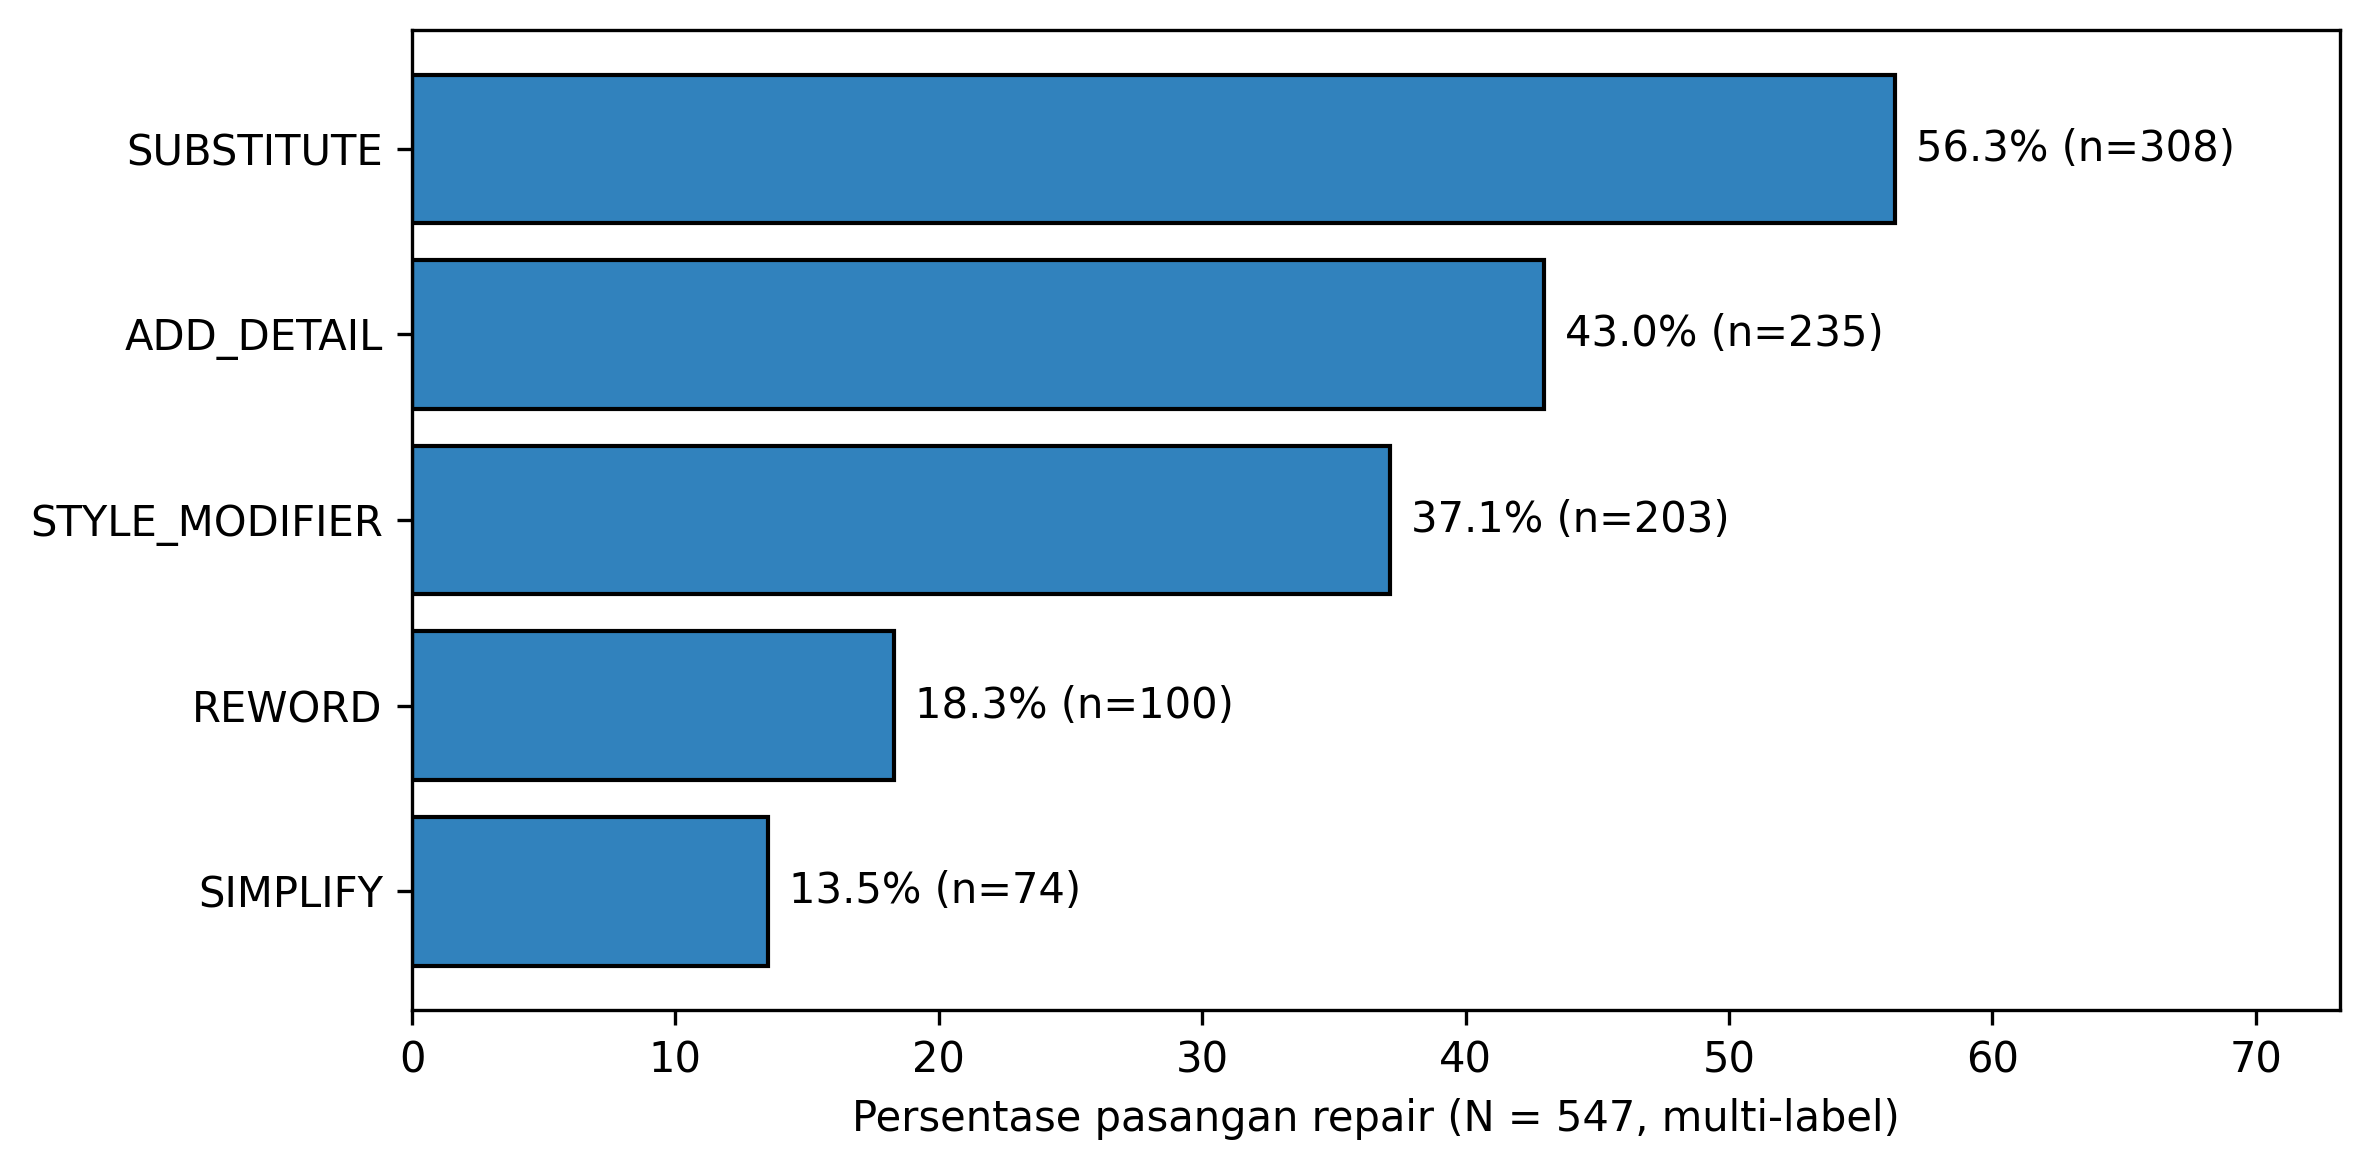

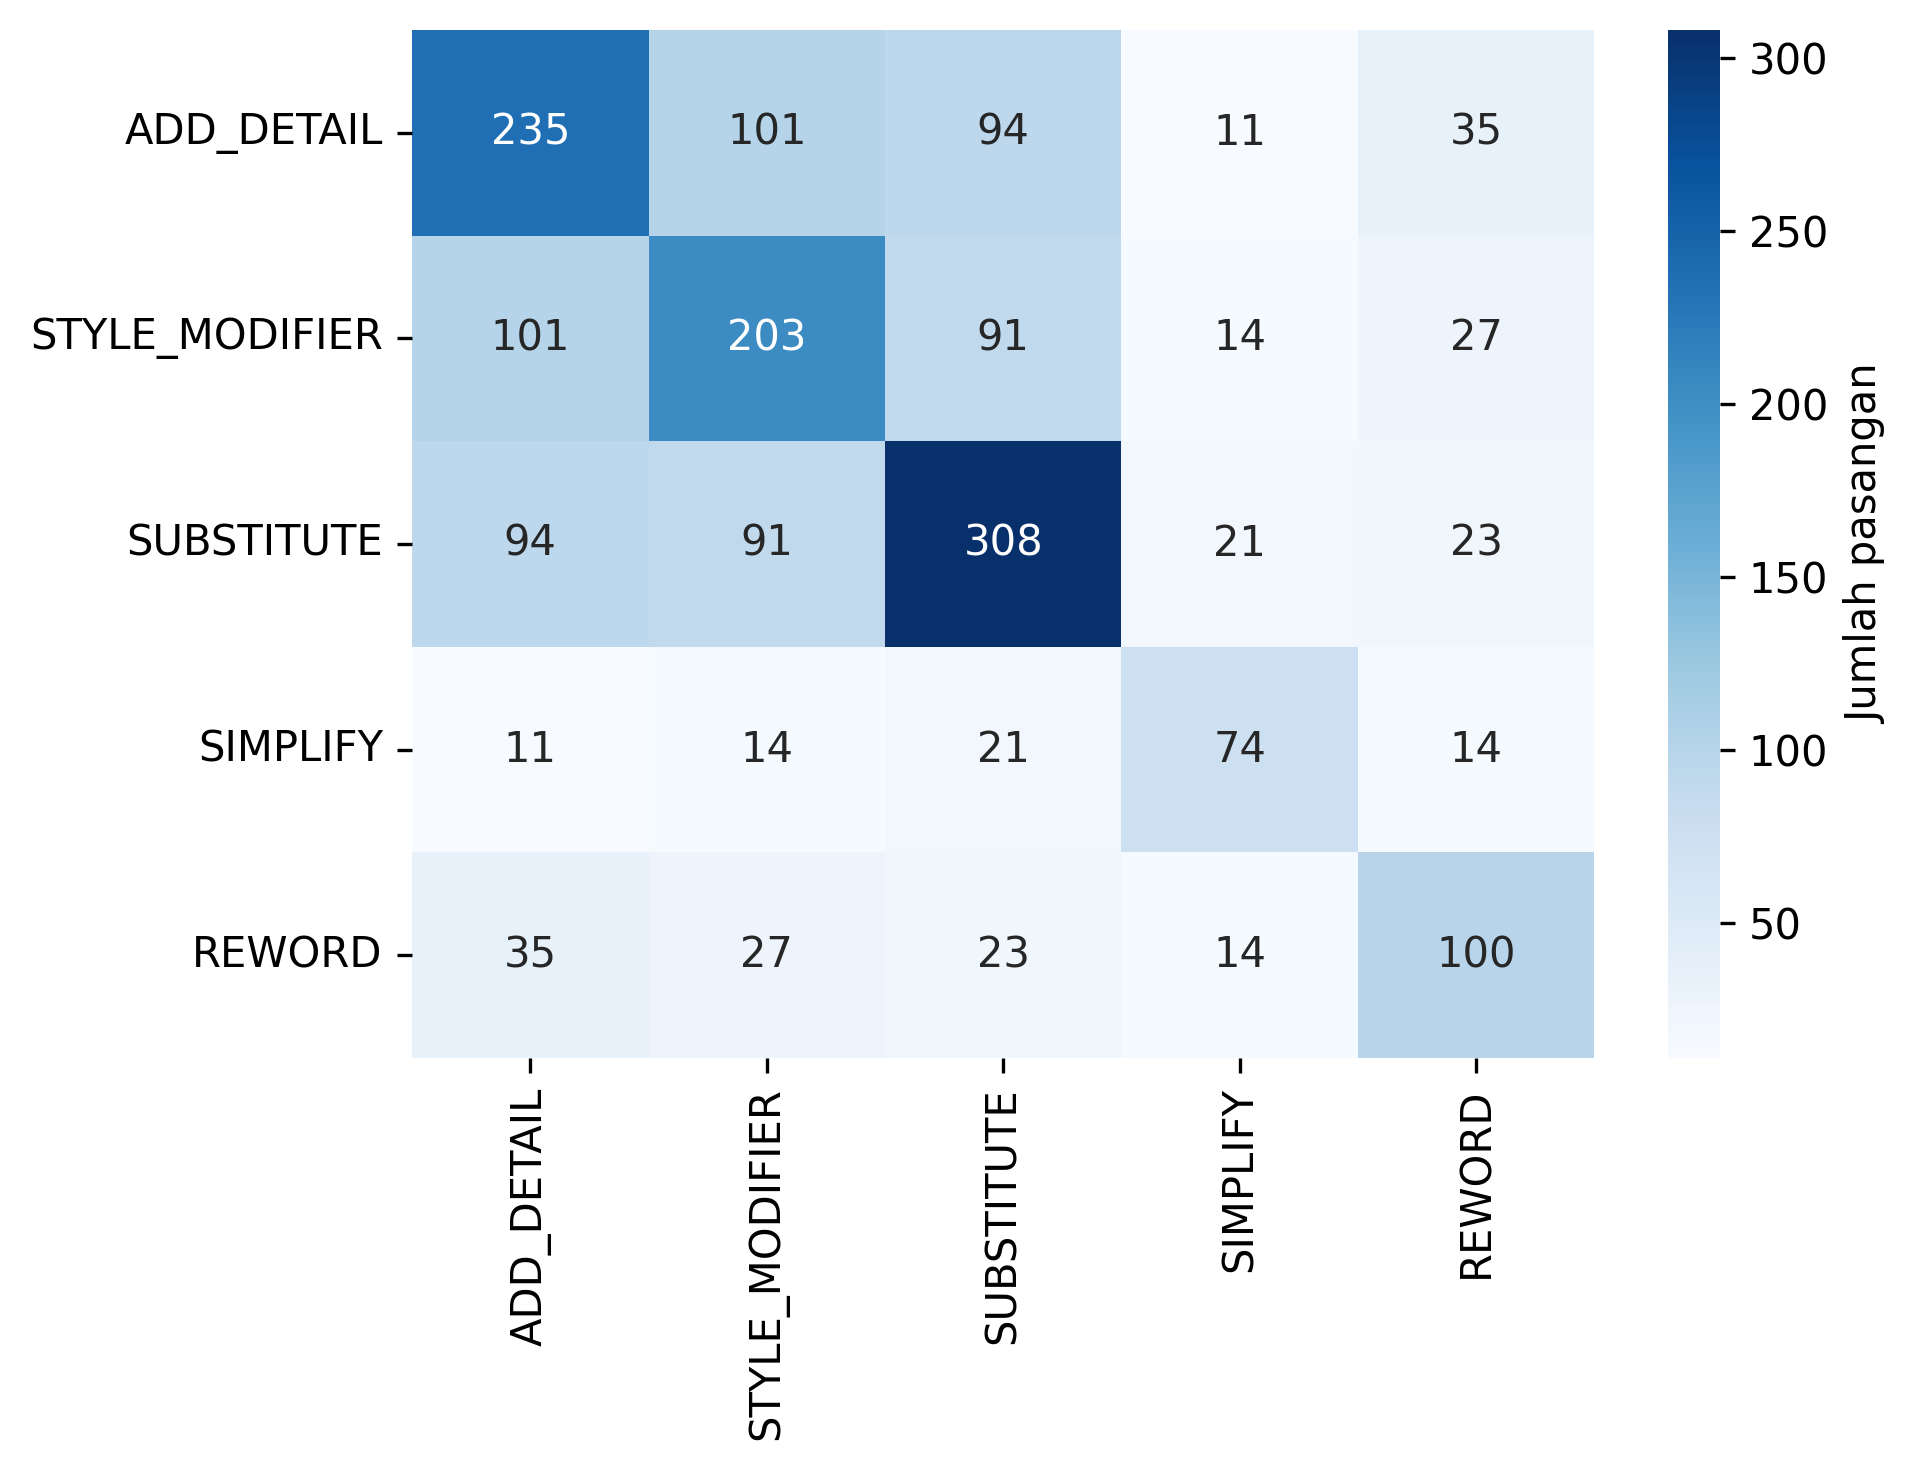

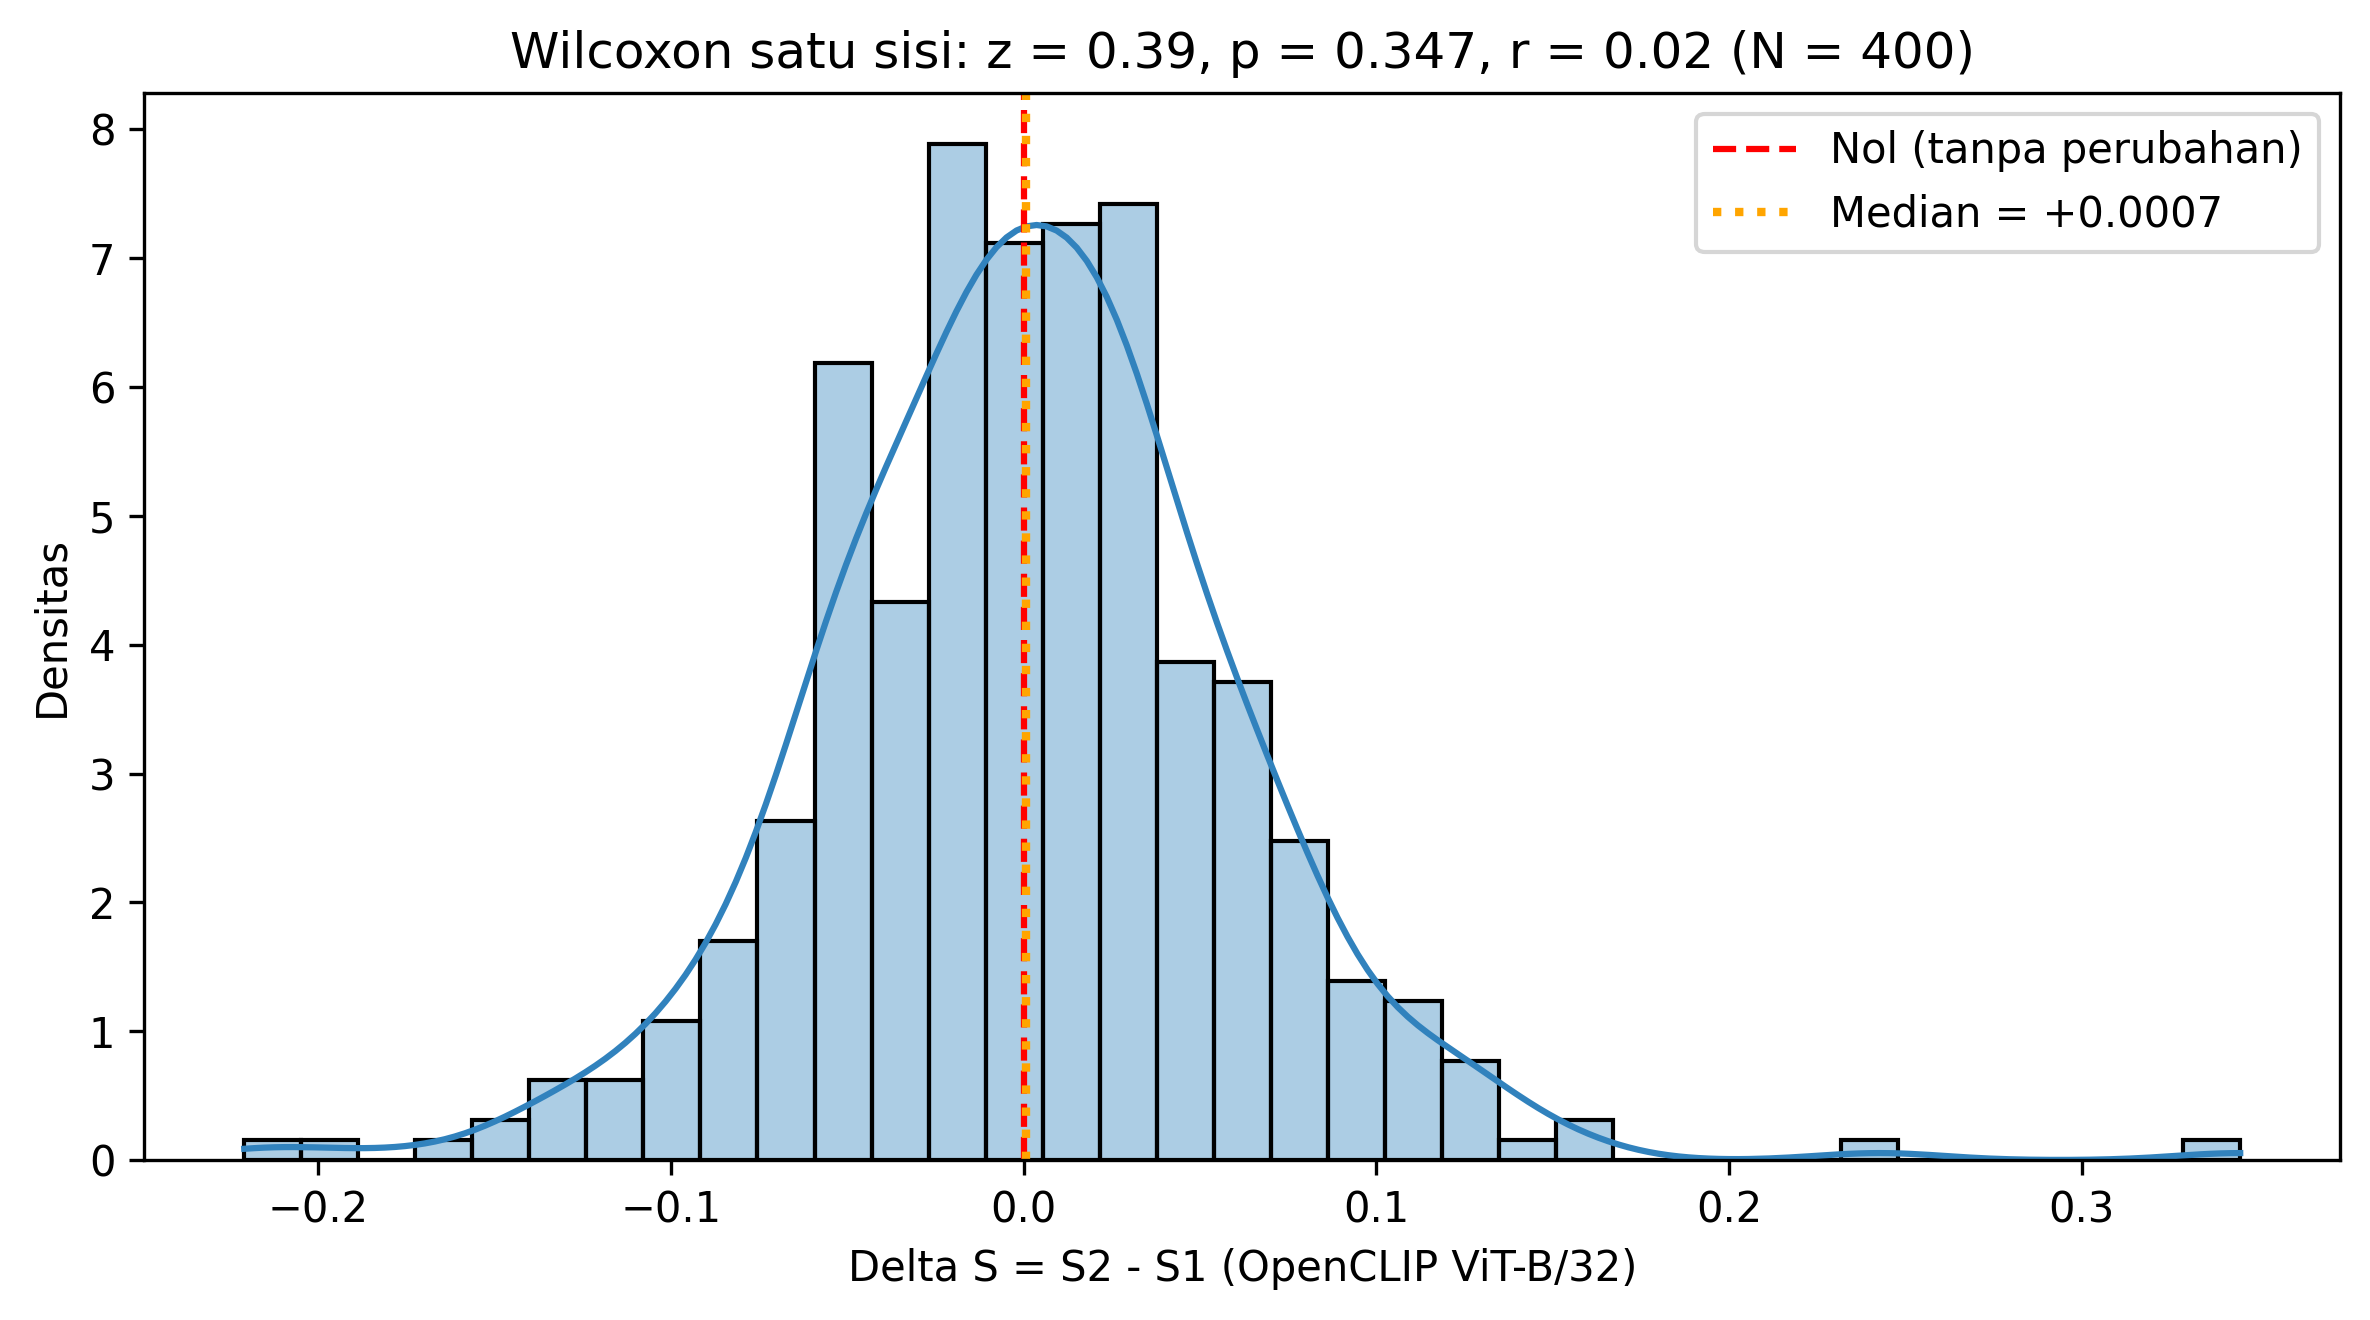

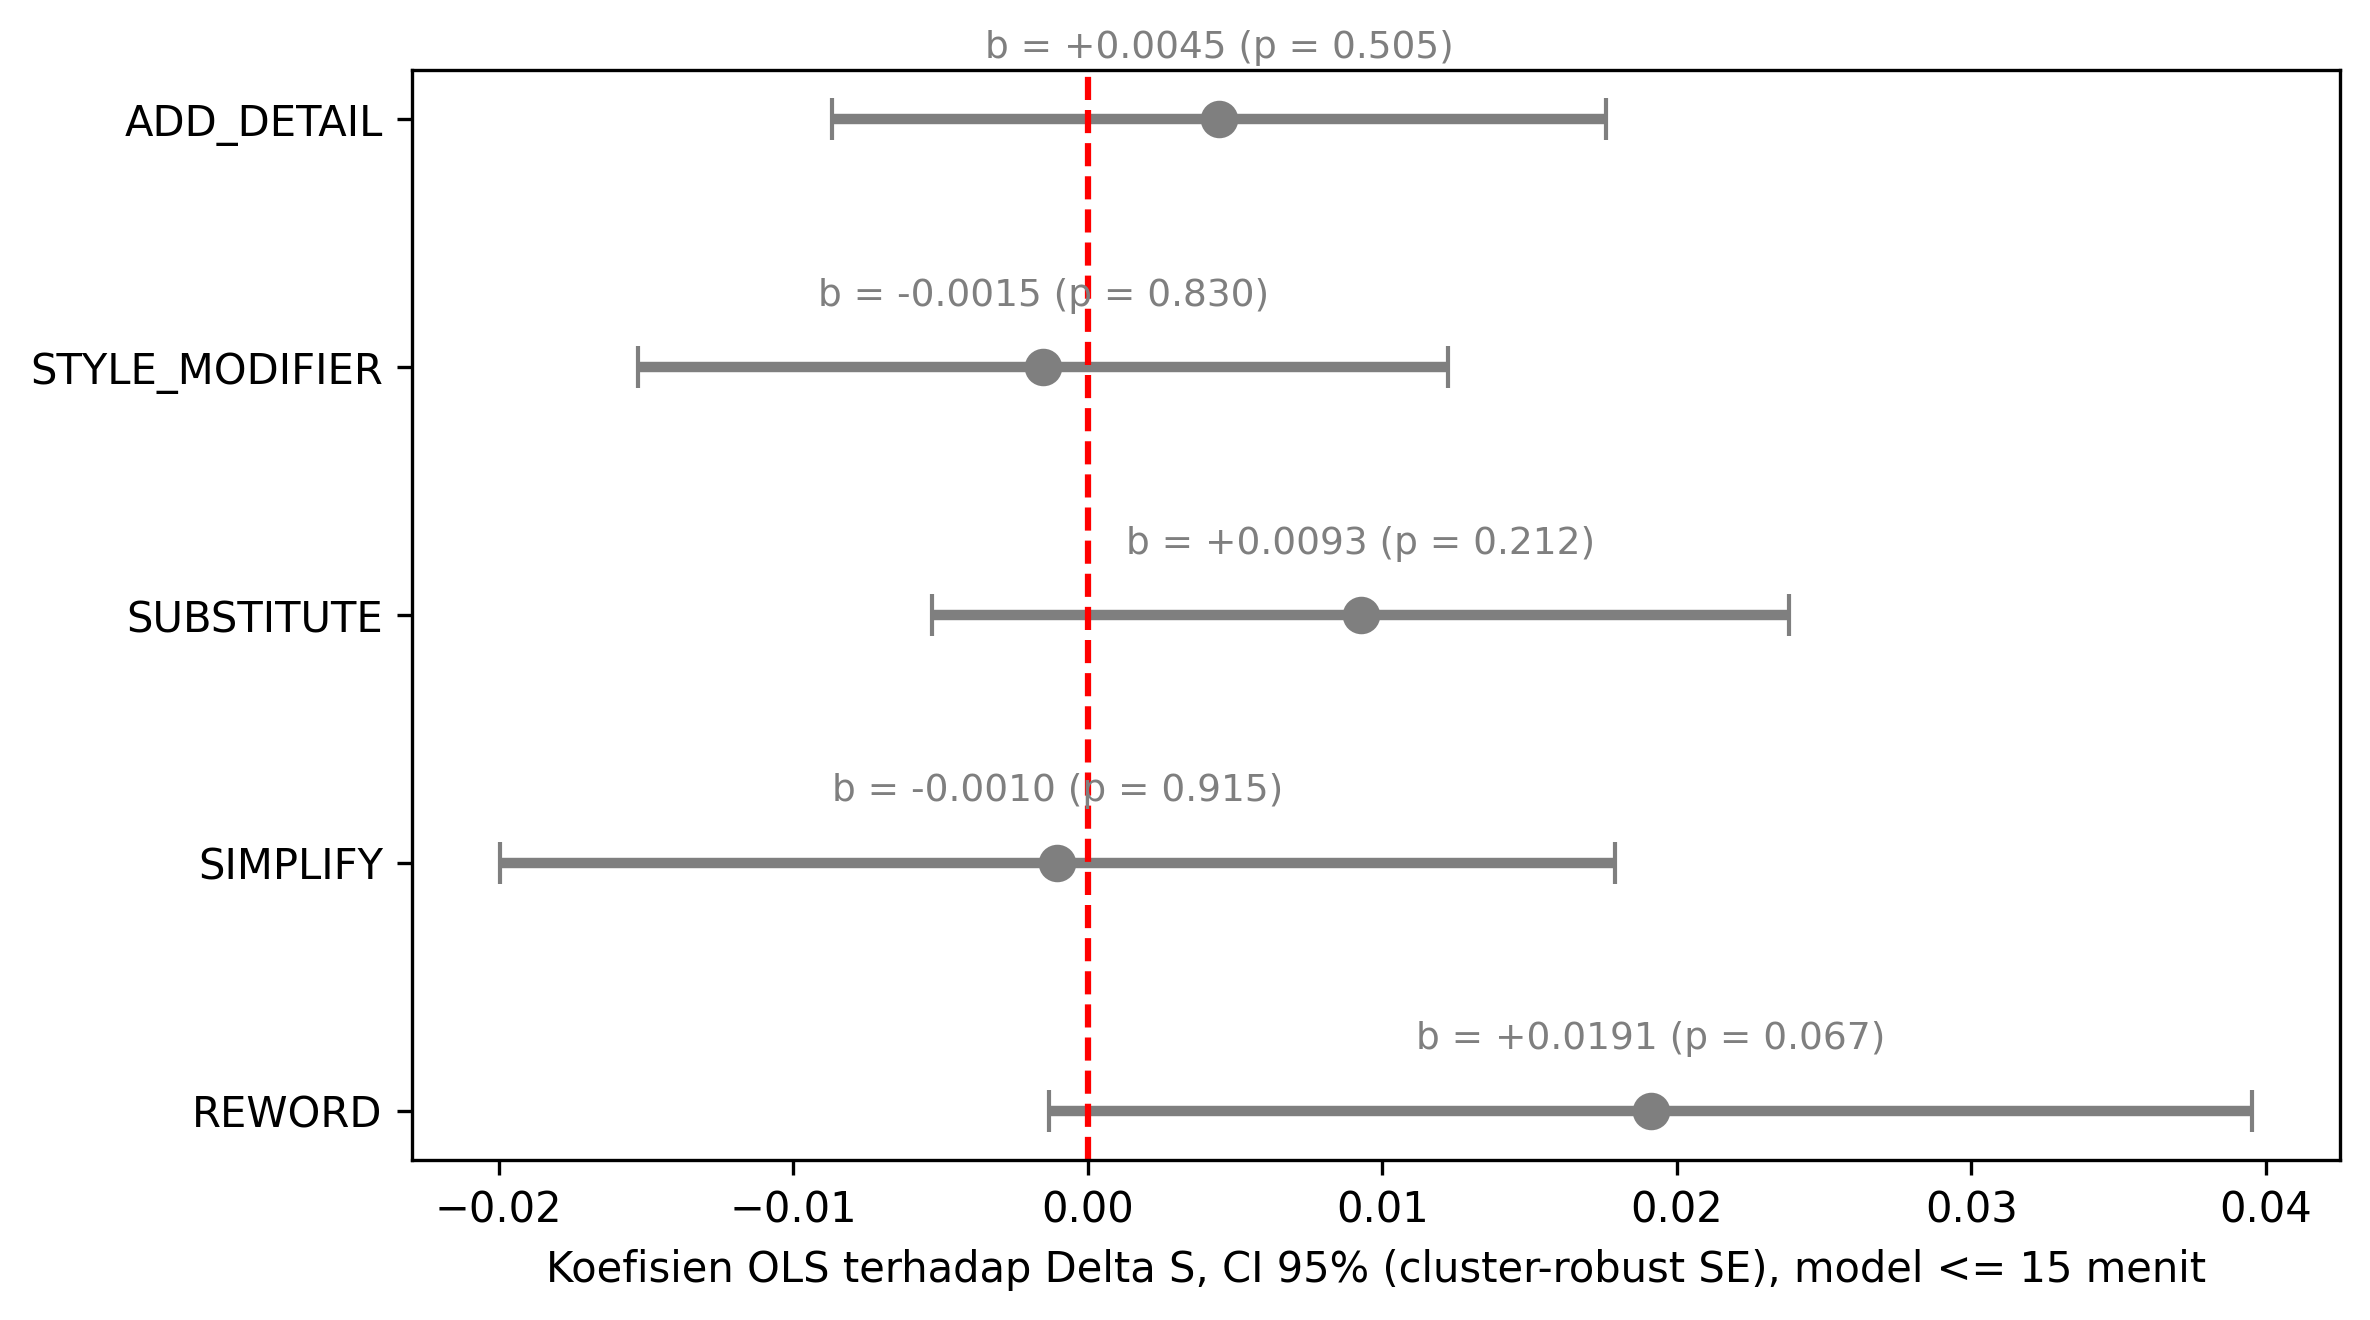

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 10, 'figure.dpi': 300})
fig_dir = P / 'results' / 'figures'
fig_dir.mkdir(parents=True, exist_ok=True)
rep = df_analysis[df_analysis['NOT_REPAIR'] == 0]

# Gambar 1: distribusi strategi (RQ1)
pct = (rep[TAXONOMY_STRATEGIES].mean() * 100).sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(pct.index, pct.values, color='#3182bd', edgecolor='black')
for i, (s, v) in enumerate(pct.items()):
    ax.text(v + 0.8, i, f'{v:.1f}% (n={int(rep[s].sum())})', va='center')
ax.set_xlim(0, pct.max() * 1.3)
ax.set_xlabel(f'Persentase pasangan repair (N = {len(rep)}, multi-label)')
plt.tight_layout(); plt.savefig(fig_dir / 'fig1_rq1_distribusi_taksonomi.png', dpi=300); plt.show()

# Gambar 2: ko-okurensi (RQ1)
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(co_matrix, annot=True, fmt='d', cmap='Blues', ax=ax, cbar_kws={'label': 'Jumlah pasangan'})
plt.tight_layout(); plt.savefig(fig_dir / 'fig2_rq1_heatmap_ko_okurensi.png', dpi=300); plt.show()

# Gambar 3: distribusi Delta S (RQ2) -- seluruh angka diambil dari hasil hitung
delta = df_multimodal['delta_clip']
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(delta, kde=True, bins=35, stat='density', color='#3182bd', alpha=0.4, ax=ax)
ax.axvline(0, color='red', ls='--', label='Nol (tanpa perubahan)')
ax.axvline(delta.median(), color='orange', ls=':', lw=2, label=f'Median = {delta.median():+.4f}')
_p = res_rq2['Wilcoxon_p_satu_sisi']
ax.set_title(f'Wilcoxon satu sisi: z = {res_rq2["Wilcoxon_z"]:.2f}, p = {_p:.3g}, r = {res_rq2["Effect_Size_r"]:.2f} (N = {len(delta)})')
ax.set_xlabel('Delta S = S2 - S1 (OpenCLIP ViT-B/32)'); ax.set_ylabel('Densitas'); ax.legend()
plt.tight_layout(); plt.savefig(fig_dir / 'fig3_rq2_distribusi_delta_clip.png', dpi=300); plt.show()

# Gambar 4: forest plot koefisien (RQ3)
fig, ax = plt.subplots(figsize=(8, 4.5))
ci = mod_15.conf_int()
for i, v in enumerate(TAXONOMY_STRATEGIES):
    c, p = mod_15.params[v], mod_15.pvalues[v]
    col = '#2ca02c' if (p < 0.05 and c > 0) else '#d62728' if p < 0.05 else '#7f7f7f'
    ax.errorbar(c, i, xerr=[[c - ci.loc[v, 0]], [ci.loc[v, 1] - c]], fmt='o', color=col, capsize=5, elinewidth=2.5, markersize=8)
    ax.text(c, i - 0.25, f'b = {c:+.4f} (p = {p:.3f})', ha='center', fontsize=9, color=col)
ax.axvline(0, color='red', ls='--')
ax.set_yticks(range(len(TAXONOMY_STRATEGIES))); ax.set_yticklabels(TAXONOMY_STRATEGIES); ax.invert_yaxis()
ax.set_xlabel('Koefisien OLS terhadap Delta S, CI 95% (cluster-robust SE), model <= 15 menit')
plt.tight_layout(); plt.savefig(fig_dir / 'fig4_rq3_forest_plot_regresi.png', dpi=300); plt.show()


## Bagian 16b — Gambar versi bahasa Inggris
Untuk manuskrip bahasa Inggris. Disimpan dengan akhiran `_en`.


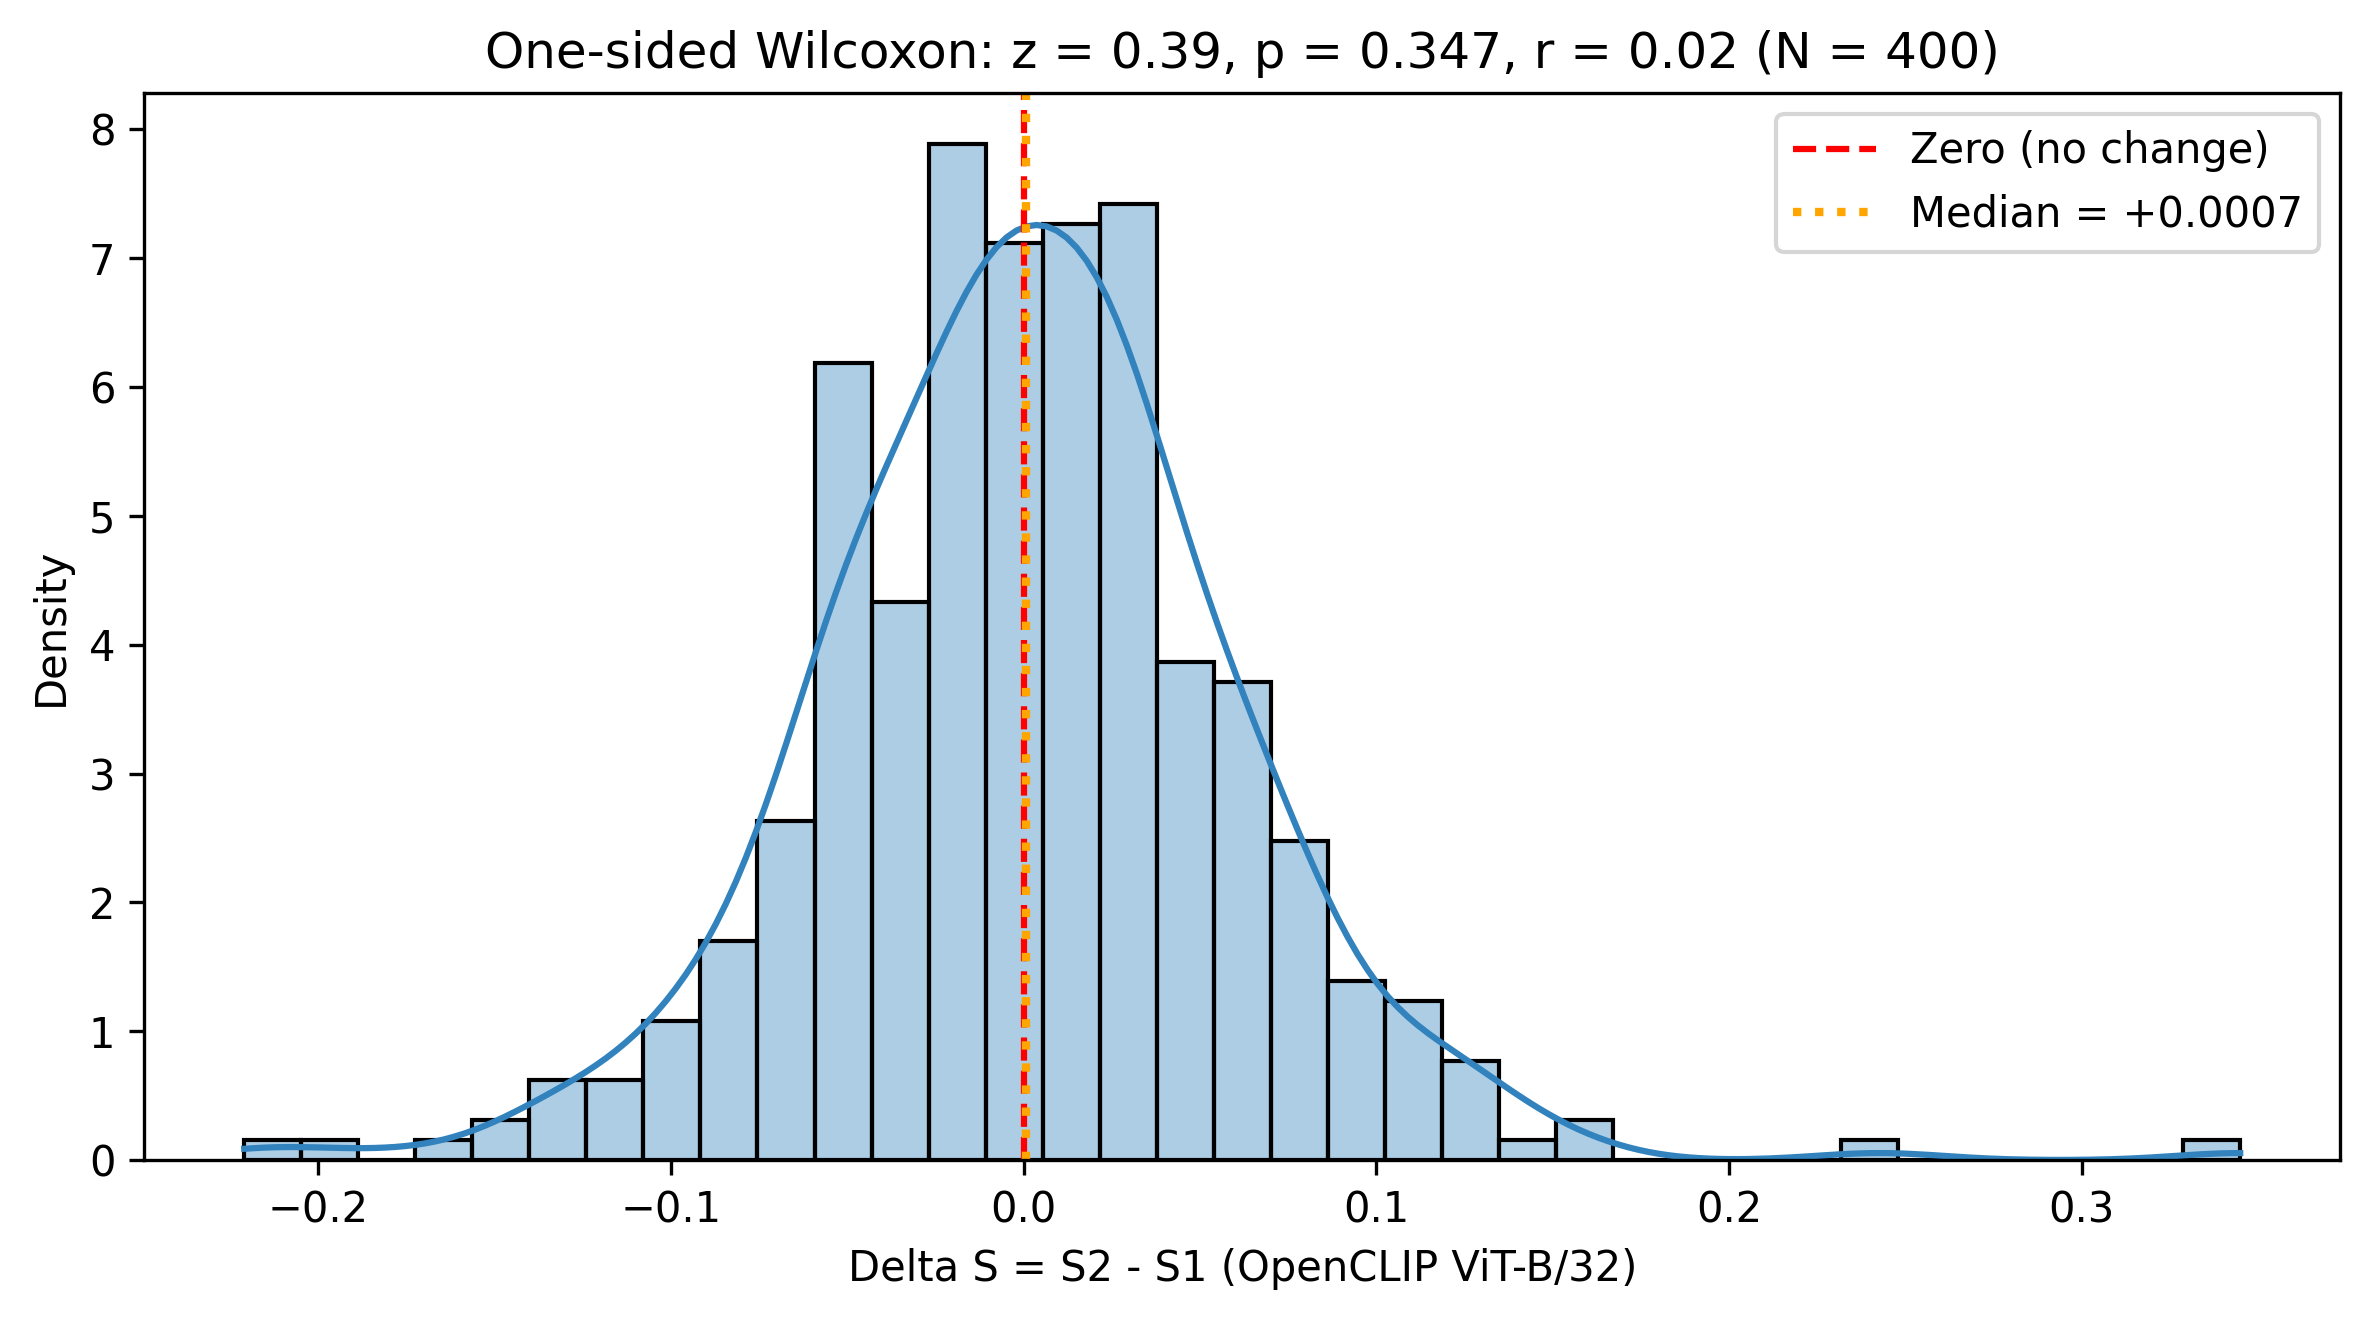

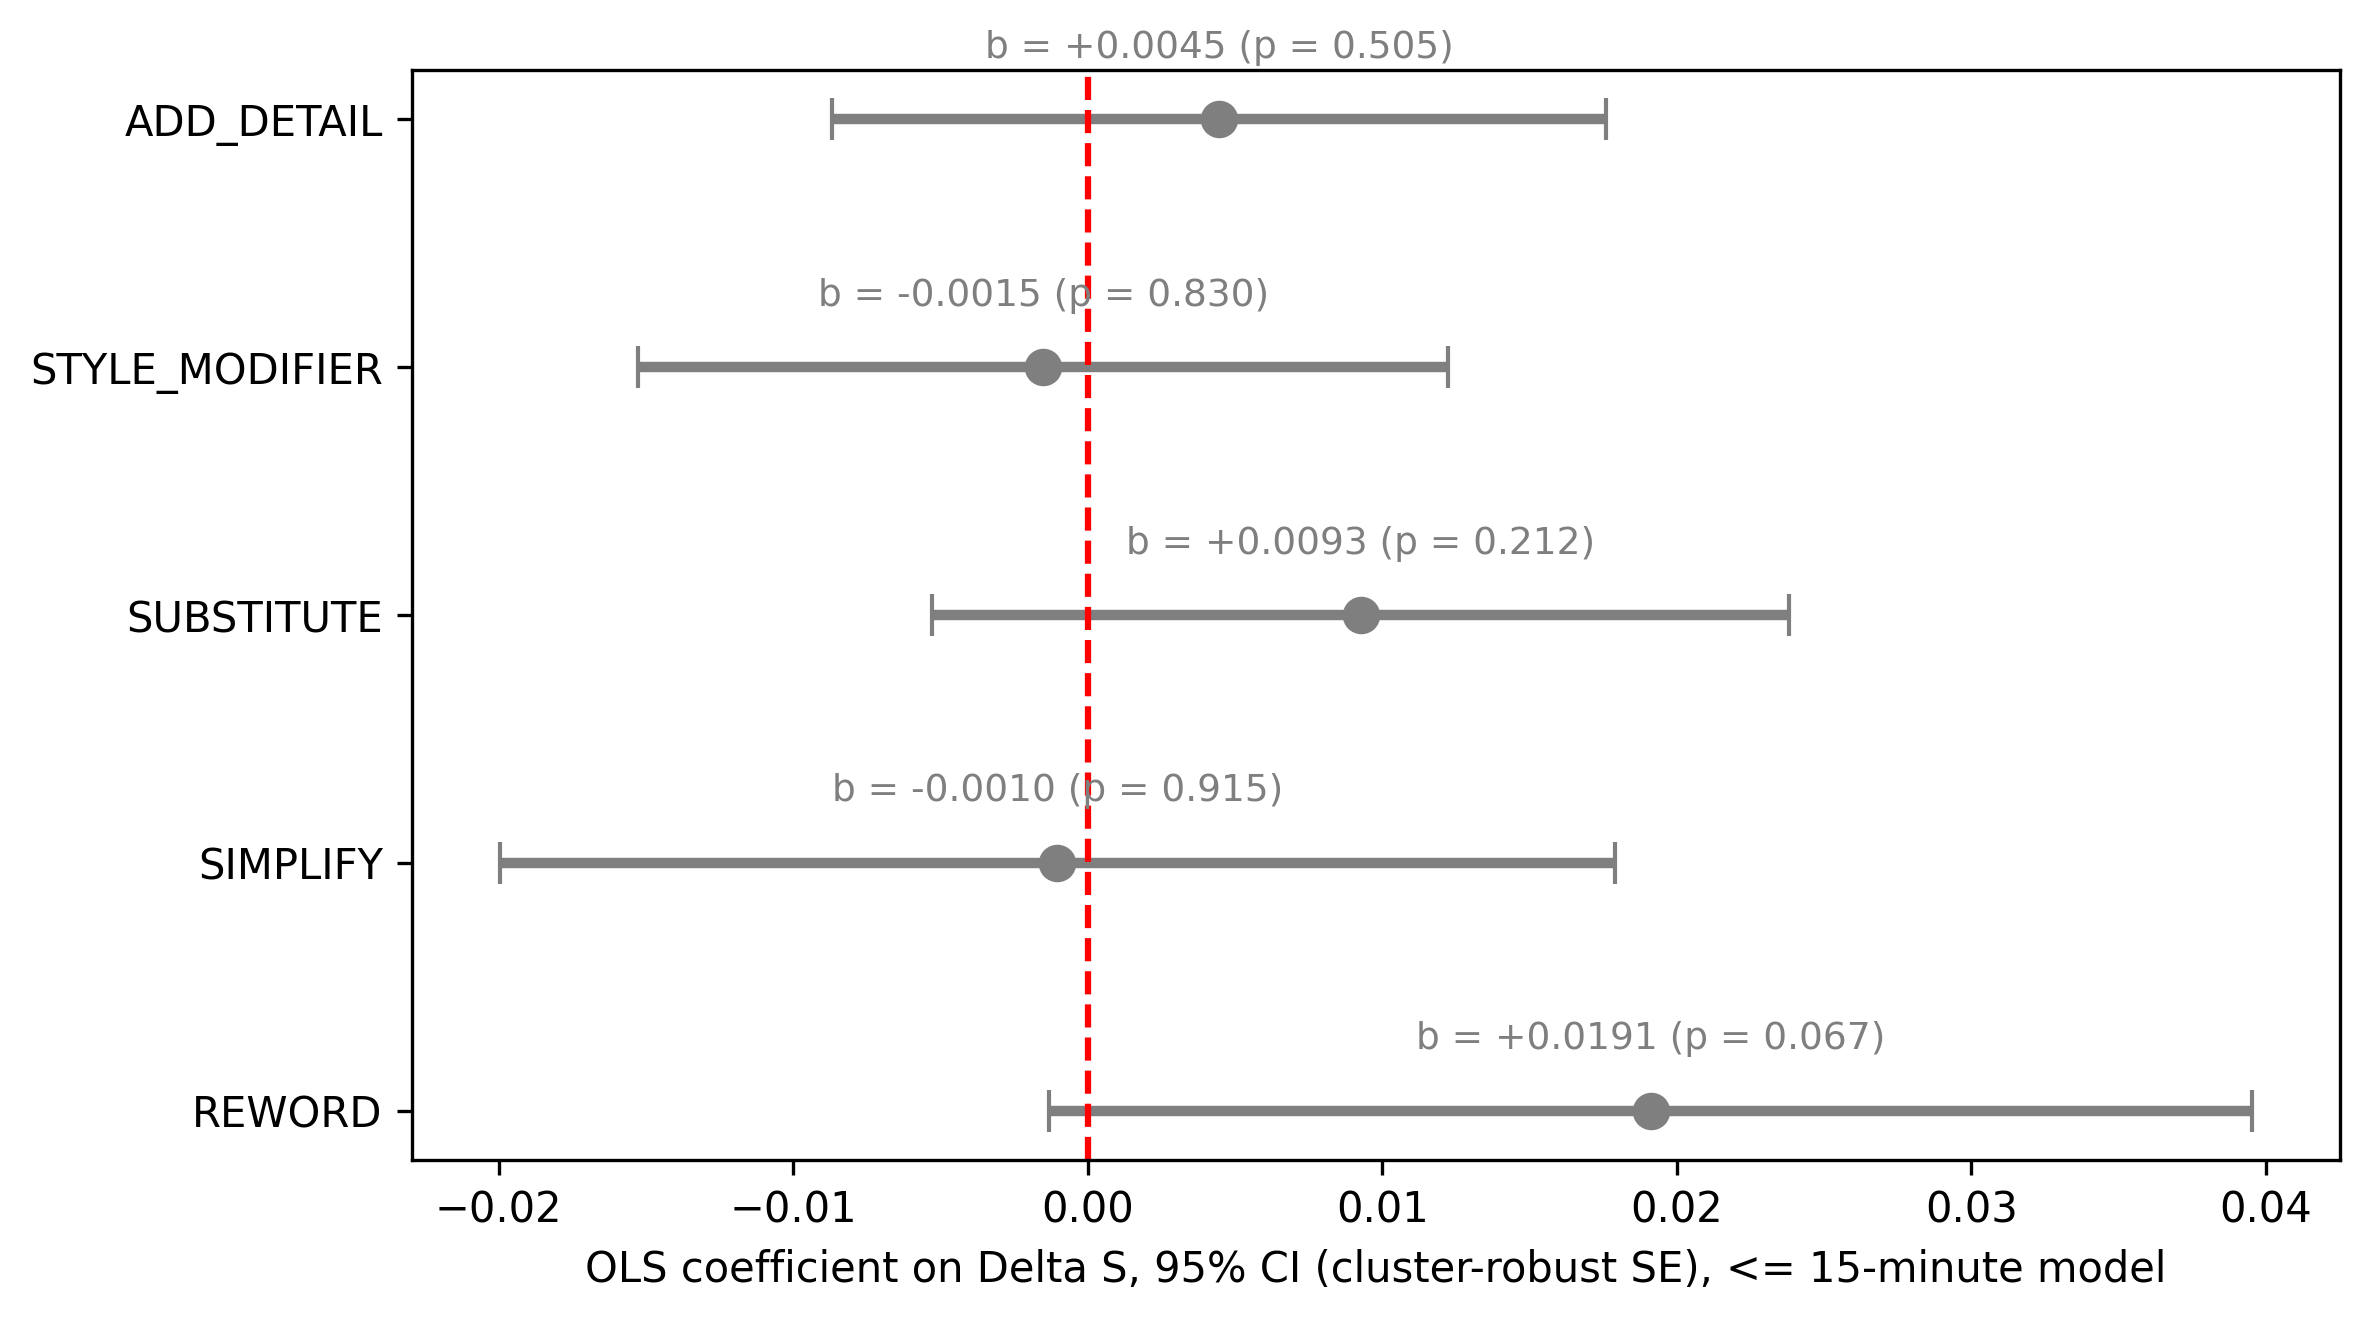

In [21]:
delta = df_multimodal['delta_clip']
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(delta, kde=True, bins=35, stat='density', color='#3182bd', alpha=0.4, ax=ax)
ax.axvline(0, color='red', ls='--', label='Zero (no change)')
ax.axvline(delta.median(), color='orange', ls=':', lw=2, label=f'Median = {delta.median():+.4f}')
ax.set_title(f'One-sided Wilcoxon: z = {res_rq2["Wilcoxon_z"]:.2f}, p = {res_rq2["Wilcoxon_p_satu_sisi"]:.3g}, r = {res_rq2["Effect_Size_r"]:.2f} (N = {len(delta)})')
ax.set_xlabel('Delta S = S2 - S1 (OpenCLIP ViT-B/32)'); ax.set_ylabel('Density'); ax.legend()
plt.tight_layout(); plt.savefig(fig_dir / 'fig3_rq2_distribusi_delta_clip_en.png', dpi=300); plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
ci = mod_15.conf_int()
for i, v in enumerate(TAXONOMY_STRATEGIES):
    c, p = mod_15.params[v], mod_15.pvalues[v]
    col = '#2ca02c' if (p < 0.05 and c > 0) else '#d62728' if p < 0.05 else '#7f7f7f'
    ax.errorbar(c, i, xerr=[[c - ci.loc[v, 0]], [ci.loc[v, 1] - c]], fmt='o', color=col, capsize=5, elinewidth=2.5, markersize=8)
    ax.text(c, i - 0.25, f'b = {c:+.4f} (p = {p:.3f})', ha='center', fontsize=9, color=col)
ax.axvline(0, color='red', ls='--')
ax.set_yticks(range(len(TAXONOMY_STRATEGIES))); ax.set_yticklabels(TAXONOMY_STRATEGIES); ax.invert_yaxis()
ax.set_xlabel('OLS coefficient on Delta S, 95% CI (cluster-robust SE), <= 15-minute model')
plt.tight_layout(); plt.savefig(fig_dir / 'fig4_rq3_forest_plot_regresi_en.png', dpi=300); plt.show()


## Bagian 16c — Lembar Isi Manuskrip (otomatis)
Membaca seluruh tabel di `results/` dan menulis `LEMBAR_ISI_ID.md` serta `LEMBAR_ISI_EN.md`: nilai tiap placeholder manuskrip, sudah dibulatkan dan diformat (koma desimal untuk Indonesia, titik untuk Inggris), beserta keputusan H1–H3. Sel ini boleh dijalankan ulang kapan saja, misalnya setelah validasi penilai selesai.


In [22]:
def buat_lembar_isi(lang):
    R = P / 'results'
    idn = lang == 'id'

    def f(x, d=3):
        if x is None or pd.isna(x): return '-'
        s = f'{float(x):.{d}f}'
        return s.replace('.', ',') if idn else s

    def fp(p):
        if pd.isna(p): return '-'
        return ('< 0,001' if idn else '< 0.001') if p < 0.001 else f(p, 3)

    def n_(x):
        s = f'{int(x):,}'
        return s.replace(',', '.') if idn else s

    out = ['# ' + ('LEMBAR ISI MANUSKRIP (Indonesia)' if idn else 'MANUSCRIPT FILL-IN SHEET (English)'), '',
           ('Semua nilai dihitung oleh notebook v2 dari data nyata.' if idn else 'All values computed by the v2 notebook from real data.'), '']

    alur = pd.read_csv(R / 'tabel_alur_sampel.csv')
    out += ['## Tabel 2 / Table 2', '', '| Tahap | Jumlah |', '|---|---|'] + [f'| {t} | {n_(j)} |' for t, j in zip(alur['Tahap'], alur['Jumlah'])] + ['']

    rq1 = pd.read_csv(R / 'tabel_rq1_distribusi_taksonomi.csv', index_col=0)
    kfile = R / 'tabel_cohen_kappa_validasi.csv'
    kap = pd.read_csv(kfile).set_index('Label') if kfile.exists() else None
    out += ['## Tabel 3 / Table 3', '', '| Strategi | n | % (CI 95%) | Po (%) | kappa antarpenilai | PABAK | kappa LLM-penilai |', '|---|---|---|---|---|---|---|']
    for s in TAXONOMY_STRATEGIES:
        r = rq1.loc[s]
        pct = f'{f(r.iloc[1], 1)} ({f(r.iloc[2], 1)}–{f(r.iloc[3], 1)})'
        if kap is not None:
            k = kap.loc[s]
            kk = [f(k['Po (%)'], 1), f(k['Kappa_P1_vs_P2'], 2), f(k['PABAK'], 2), f((k['Kappa_LLM_vs_P1'] + k['Kappa_LLM_vs_P2']) / 2, 2)]
        else:
            kk = ['BELUM ADA'] * 4
        out.append(f'| {s} | {n_(r.iloc[0])} | {pct} | ' + ' | '.join(kk) + ' |')
    if kap is None:
        out += ['', '**Kappa BELUM ADA: lengkapi validasi dua penilai (Bagian 15), lalu jalankan ulang sel ini.**']
    else:
        ks = kap.loc[TAXONOMY_STRATEGIES, 'Kappa_P1_vs_P2']
        out += ['', f'- kappa min–maks: {f(ks.min(), 2)}–{f(ks.max(), 2)}; rata-rata: {f(ks.mean(), 2)}; tertinggi: {ks.idxmax()}; terendah: {ks.idxmin()}',
                f'- Label dengan kappa < 0,60: {", ".join(ks[ks < 0.60].index) or "tidak ada"}']
    not_rep = rq1.loc['NOT_REPAIR']
    nl = pd.read_csv(R / 'tabel_rq1_jumlah_label.csv', index_col=0).iloc[:, 0]
    co = pd.read_csv(R / 'tabel_rq1_ko_okurensi_multilabel.csv', index_col=0)
    best = max(((a, b, co.loc[a, b]) for i, a in enumerate(TAXONOMY_STRATEGIES) for b in TAXONOMY_STRATEGIES[i + 1:]), key=lambda t: t[2])
    out += [f'- NOT_REPAIR: {n_(not_rep.iloc[0])} ({f(not_rep.iloc[4], 1)}% pool)',
            f'- Pasangan dengan > 1 strategi: {f(nl[nl.index > 1].sum() / nl.sum() * 100, 1)}%',
            f'- Kombinasi tersering: {best[0]} + {best[1]} ({n_(best[2])} pasangan)', '']

    q = pd.read_csv(R / 'tabel_rq2_wilcoxon_multimodal.csv').iloc[0]
    h1 = (q['Wilcoxon_p_satu_sisi'] < 0.05) and (q['Median_Delta_S'] > 0)
    out += ['## RQ2 (3.3)', '',
            f'- N = {n_(q["N_Pasang"])}', f'- S1: mean {f(q["Mean_S1"])} (SD {f(q["SD_S1"])})', f'- S2: mean {f(q["Mean_S2"])} (SD {f(q["SD_S2"])})',
            f'- Median Delta S = {f(q["Median_Delta_S"], 4)} (CI 95% {f(q["Median_CI95_bawah"], 4)}–{f(q["Median_CI95_atas"], 4)}); mean = {f(q["Mean_Delta_S"], 4)}',
            f'- Delta S positif: {f(q["Proporsi_Delta_Positif"] * 100, 1)}%',
            f'- Wilcoxon: z = {f(q["Wilcoxon_z"], 2)}, p = {fp(q["Wilcoxon_p_satu_sisi"])}, r = {f(q["Effect_Size_r"], 2)}',
            f'- **H1: {"DIDUKUNG / SUPPORTED" if h1 else "TIDAK DIDUKUNG / NOT SUPPORTED"}**', '']

    side = pd.read_csv(R / 'tabel_regresi_crse_side_by_side.csv', index_col=0)
    info = pd.read_csv(R / 'tabel_regresi_info_model.csv').set_index('Model')
    vif = pd.read_csv(R / 'tabel_vif_multikolinearitas.csv')
    a, b = '(<= 15m)', '(<= 30m)'
    out += ['## Tabel 4 / Table 4', '', f'VIF maks = {f(vif["VIF"].max(), 2)}', '',
            '| Variabel | b (<=15) | CRSE | CI 95% | p | b (<=30) | p |', '|---|---|---|---|---|---|---|']
    for v in TAXONOMY_STRATEGIES + ['delta_seed', 'delta_cfg', 'delta_step', 'delta_t_min', 'Intercept']:
        r = side.loc[v]
        out.append(f'| {v} | {f(r[f"Koefisien {a}"], 4)} | {f(r[f"CRSE {a}"], 4)} | {f(r[f"CI95_bawah {a}"], 4)} – {f(r[f"CI95_atas {a}"], 4)} | {fp(r[f"p-value {a}"])} | {f(r[f"Koefisien {b}"], 4)} | {fp(r[f"p-value {b}"])} |')
    for m in ['<= 15m', '<= 30m']:
        i = info.loc[m]
        out.append(f'- Model {m}: N = {n_(i["N"])}, klaster = {n_(i["Klaster_pengguna"])}, R2 = {f(i["R2"])}, Wald p = {fp(i["Wald_p"])}')
    r = side.loc['ADD_DETAIL']; r2 = side.loc['STYLE_MODIFIER']; wp = info.loc['<= 15m', 'Wald_p']
    h2 = (r[f'Koefisien {a}'] > 0) and (r[f'p-value {a}'] < 0.05)
    h3 = (r2[f'Koefisien {a}'] < r[f'Koefisien {a}']) and (wp < 0.05)
    sig = [v for v in TAXONOMY_STRATEGIES if side.loc[v, f'p-value {a}'] < 0.05]
    out += ['', f'- **H2: {"DIDUKUNG / SUPPORTED" if h2 else "TIDAK DIDUKUNG / NOT SUPPORTED"}**',
            f'- **H3: {"DIDUKUNG / SUPPORTED" if h3 else "TIDAK DIDUKUNG / NOT SUPPORTED"}**',
            '- Strategi signifikan (p < 0,05): ' + (', '.join(f'{v} ({"+" if side.loc[v, f"Koefisien {a}"] > 0 else "-"})' for v in sig) or 'tidak ada'),
            '- Strategi tidak signifikan: ' + (', '.join(v for v in TAXONOMY_STRATEGIES if v not in sig) or 'tidak ada'), '']
    path = R / f'LEMBAR_ISI_{lang.upper()}.md'
    path.write_text('\n'.join(out).replace('= <', '<'), encoding='utf-8')
    return path

for _l in ('id', 'en'):
    print('Tersimpan:', buat_lembar_isi(_l))
print((P / 'results' / 'LEMBAR_ISI_ID.md').read_text(encoding='utf-8'))


Tersimpan: /content/drive/MyDrive/Skripsi_Conversational_Repair/results/LEMBAR_ISI_ID.md
Tersimpan: /content/drive/MyDrive/Skripsi_Conversational_Repair/results/LEMBAR_ISI_EN.md
# LEMBAR ISI MANUSKRIP (Indonesia)

Semua nilai dihitung oleh notebook v2 dari data nyata.

## Tabel 2 / Table 2

| Tahap | Jumlah |
|---|---|
| Rekaman metadata DiffusionDB 2M | 2.000.000 |
| Kandidat pasangan berurutan (dt <= 30 menit, maks. 3/pengguna) | 27.114 |
| Lolos filter SBERT awal [0.3, 0.9] | 11.738 |
| Pool acak yang dianotasi LLM | 1.000 |
| Memiliki label LLM yang valid | 1.000 |
| Sim_SBERT >= 0.5 (kriteria proposal) | 659 |
| Lolos filter NSFW (< 0.5) | 576 |
| Pasangan repair (bukan NOT_REPAIR) | 547 |
| Sampel multimodal Tier 2 | 400 |

## Tabel 3 / Table 3

| Strategi | n | % (CI 95%) | Po (%) | kappa antarpenilai | PABAK | kappa LLM-penilai |
|---|---|---|---|---|---|---|
| ADD_DETAIL | 235 | 43,0 (38,8–47,1) | 82,5 | 0,61 | 0,65 | 0,53 |
| STYLE_MODIFIER | 203 | 37,1 (33,1–41,2) | 79,0 | 0

## Bagian 17 — Ringkasan Akhir


In [23]:
ringkasan = {
    'sumber_skor_clip': 'OpenCLIP ViT-B/32 laion2b_s34b_b79k, inferensi nyata pada seluruh pasangan (tanpa nilai cadangan)',
    'N_pool_analisis': int(N_POOL), 'N_repair': int(N_REPAIR), 'N_tier2': int(len(df_multimodal)),
    'pengguna_unik_tier2': int(df_multimodal['user_id'].nunique()),
    'rq2': {k: float(v) for k, v in res_rq2.items()},
    'kappa_tersedia': df_kappa is not None,
}
(P / 'results' / 'ringkasan_hasil.json').write_text(json.dumps(ringkasan, indent=2))
print(json.dumps(ringkasan, indent=2))
print('\nSelesai. Seluruh tabel ada di results/, gambar di results/figures/.')
if df_kappa is None:
    print('CATATAN: Cohen Kappa BELUM ada. Lengkapi validasi dua penilai (Bagian 15) sebelum naskah dikirim.')


{
  "sumber_skor_clip": "OpenCLIP ViT-B/32 laion2b_s34b_b79k, inferensi nyata pada seluruh pasangan (tanpa nilai cadangan)",
  "N_pool_analisis": 576,
  "N_repair": 547,
  "N_tier2": 400,
  "pengguna_unik_tier2": 390,
  "rq2": {
    "N_Pasang": 400.0,
    "Mean_S1": 0.3448883622791618,
    "SD_S1": 0.04977799774586761,
    "Mean_S2": 0.3463213299959898,
    "SD_S2": 0.046081936044621304,
    "Mean_Delta_S": 0.0014329677168279887,
    "Median_Delta_S": 0.0007455497980117798,
    "Std_Delta_S": 0.06017659148016445,
    "Median_CI95_bawah": -0.005990579724311829,
    "Median_CI95_atas": 0.0071919262409210205,
    "Proporsi_Delta_Positif": 0.5075,
    "Shapiro_Wilk_p": 2.6367477272284524e-07,
    "Wilcoxon_W_plus": 41011.0,
    "Wilcoxon_z": 0.393736392445702,
    "Wilcoxon_p_satu_sisi": 0.3468878349782285,
    "Effect_Size_r": 0.0196868196222851,
    "Rank_Biserial": 0.022718204488778055
  },
  "kappa_tersedia": true
}

Selesai. Seluruh tabel ada di results/, gambar di results/figures/.
